# 02. Legacy: группы котлов, сценарии и сравнение моделей

Старые analogs, AAKR и MSET: прежние параметры и нормализация. По умолчанию включено быстрое обновление калибровки; прежний режим доступен для сравнения.
Основной котёл выбирать не нужно: проверяются все котлы выбранных групп.
Результаты — в таблицах и графиках этого ноутбука с раскрывающейся навигацией.

[Настройки](#settings) · [План](#plan) · [Запуск](#run) · [Сводка](#overview) · [Графики](#details) ·
[Пороги](#thresholds) · [Близость](#proximity) · [Общие часы](#paired) · [Диагностика](#diagnostics)

Архив исходного ноутбука до этой доработки — в `_archive/before_fleet_2026-10-19/`.
Локальные библиотеки находятся в `lib/`; ничего устанавливать автоматически не требуется.


In [21]:
from pathlib import Path
import os, sys, importlib
_notebook_parent = Path(globals().get('__file__', '02_Обучение.ipynb')).resolve().parent
_candidates = [_notebook_parent, Path.cwd() / 'legacy', Path.cwd().parent / 'legacy']
PROJECT_DIR = next((p for p in _candidates if (p / 'lib' / 'legacy_fleet.py').is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Откройте ноутбук из папки legacy с папкой lib.')
PROJECT_DIR = PROJECT_DIR.resolve()
os.chdir(PROJECT_DIR)
for _p in (PROJECT_DIR, PROJECT_DIR / 'lib'):
    if str(_p) in sys.path: sys.path.remove(str(_p))
    sys.path.insert(0, str(_p))
__file__ = str(PROJECT_DIR / '02_Обучение.ipynb')
import legacy_group, legacy_metrics, legacy_fleet as LF
import legacy_plots
importlib.reload(legacy_plots)
importlib.reload(legacy_group)
importlib.reload(legacy_metrics)
LF = importlib.reload(LF)
from IPython.display import display, HTML
import pandas as pd
print(LF.VERSION, '·', PROJECT_DIR)


legacy-fleet-2.2 · C:\Users\ZaprutoEA\Desktop\ЦД\legacy


<a id="settings"></a>
## 0. Настройки

`local` — каждый котёл учится на своей истории; `pooled` — одна модель на истории группы;
`transfer` — обучение на одном котле, проверка на остальных котлах той же группы.
`TRANSFER_DONORS=None` перебирает всех доноров. Группу из одного котла можно включать в общий запуск.

`LOCAL_SENSOR_SETS=['common', 'full']`: индивидуальная модель на общем наборе для честного сравнения
и отдельно на собственном наборе датчиков. Общая модель и перенос всегда используют пересечение по группе,
включая небаланс пар/вода. Названия и роли берутся из Excel.


In [22]:
CFG = LF.defaults()
CFG.update(
    # GROUPS={'БКЗ-500': ['К-5', 'К-6', 'К-7']},
    # Пример трёх независимых групп:
    GROUPS={'Группа 2': ['К-5','К-6','К-7'], 'Группа 1': ['К-1','К-2','К-3','К-4'],
            'Группа 3': ['К-8']},
    SELECT_GROUPS=None,                    # None — все группы; или ['Группа 2']
    SCENARIOS=['local', 'pooled', 'transfer'],
    LOCAL_SENSOR_SETS=['common', 'full'],
    TRANSFER_DONORS=None,                   # или {'БКЗ-500': ['К-5']}
    SENSOR_LIST_FILE='sensor_roles.xlsx',
    DATA_ROOT='opc_wide',
    DATA_PATHS={},                          # {'К-5': 'D:/data/К-5/hourly.parquet', ...}
    DATA_KIND='hourly', INSTANT_STEP='5min', INSTANT_PATHS={},
    FIRST_TEST='2025-03-01', FIRST_TEST_AUTO=False, EVAL_END=None,
    MAIN_METHODS=['analogs', 'AAKR'], #, 'MSET'
    OTHER_METHODS=[],
    # OTHER_METHODS=['AAKR (все датчики)', 'MSET (все датчики)', 'Регрессия',
    #                'Близнецы', 'Остатки analogs', 'Остатки AAKR', 'Остатки MSET'],
    RESIDUAL_BASES=['analogs', 'AAKR', 'MSET'],
    RESIDUAL_METHODS=[], # ['PCA', 'Махаланобис', 'Isolation Forest', 'AE', 'LSTM'],
    RESIDUAL_BAGGING=True, USE_NEURAL=True,
    RESIDUAL_AE_EPOCHS=30, RESIDUAL_LSTM_EPOCHS=10,
    RESIDUAL_LSTM_STEPS=24, RESIDUAL_MAX_TRAIN=8000,
    RUN_THRESHOLDS={},                      # необязательные пороги работы по котлам
    TRAIN_MODE='hours', TRAIN_HOURS=6500, TRAIN_MAX_DAYS=1095, TRAIN_DAYS=365,
    AAKR_H=0.5, MSET_H=0.7, MIN_TRAIN_COVER=0.5,
    CLEAN_WINDOW_H=168, CLEAN_MIN_HISTORY_H=24,
    CLEAN_SPIKE_FACTOR=8.0, CLEAN_FROZEN_H=24,  # фильтры используют только прошлые и текущие значения
    ALARM_Q=0.995, SMOOTH_H=6, PERSIST_H=3, MERGE_GAP_H=12,
    PRE_WINDOW_D=7, NEUTRAL_D=7, MIN_LEAD_H=3,
    WINDOWS_D=[1, 3, 7, 14, 30], ALARM_MATCH='overlap',
    THRESHOLD_MULTIPLIERS=[0.5, 0.75, 1.0, 1.25, 1.5, 2.0],
    THRESHOLD_VALIDATION_END=None,           # или дата раздела прошлой проверки и последующего контроля
    PROXIMITY_HALF_LIVES_D=[1, 3, 7, 14],
    RECOMPUTE=False, REUSE_PREVIOUS_MODEL=True, TRAIN_UPDATE='fast',
    FAST_MIN_CAL_H=72,                      # минимум часов ошибок для калибровки; иначе новый OOF-старт
    IMPORT_LEGACY_CACHE=False,              # кэш прежней очистки 2.0/2.1 несовместим с 2.2
    ALIGN_LOAD_ROLE=True,                   # сопоставить разные каналы расхода пара с ролью «нагрузка»
    RESUME_EXPERIMENTS=True, SHOW_PROGRESS_RESULTS=True,
    VERBOSE=False,                         # True — подробный журнал по месяцам
    HISTORY_MISSING='previous',             # previous / skip: экспорт не обучает пропущенные месяцы
    EXPORT=True, HISTORY_FOR=['analogs', 'AAKR', 'MSET'],
    LEGACY_OUTPUT_DIR='anomaly_results_legacy', LEGACY_MODELS_DIR='models_legacy',
    CONTINUE_ON_ERROR=True,
)
# JSON при ночном запуске переопределяет эти настройки.
CFG = LF.configuration(CFG)


<a id="plan"></a>
## 1. План и проверка входов

Таблица показывает каждый запуск: группа, сценарий, котёл проверки и котлы обучения.
Неприменимые сценарии одиночных групп не считаются ошибками.


In [23]:
PLAN = LF.plan(CFG)
display(PLAN.drop(columns=['key']))
display(LF.preflight(CFG))
print('Экспериментов:', PLAN.status.eq('запланировано').sum())


,group,scenario,target,donors,sensor_set,status
0,Группа 2,local_common,К-5,К-5,common,запланировано
1,Группа 2,local_full,К-5,К-5,full,запланировано
2,Группа 2,local_common,К-6,К-6,common,запланировано
3,Группа 2,local_full,К-6,К-6,full,запланировано
4,Группа 2,local_common,К-7,К-7,common,запланировано
5,Группа 2,local_full,К-7,К-7,full,запланировано
6,Группа 2,pooled,К-5,"К-5, К-6, К-7",common,запланировано
7,Группа 2,pooled,К-6,"К-5, К-6, К-7",common,запланировано
8,Группа 2,pooled,К-7,"К-5, К-6, К-7",common,запланировано
9,Группа 2,transfer,К-5,К-6,common,запланировано


Группа 2: общих проверяемых по Excel 172; сопоставление нагрузки по роли: False.
Группа 1: общих проверяемых по Excel 168; сопоставление нагрузки по роли: True.


,котёл,источник,строк_Excel
0,К-5,C:\Users\ZaprutoEA\Desktop\ЦД\legacy\opc_wide\К-5\hourly.parquet,244
1,К-6,C:\Users\ZaprutoEA\Desktop\ЦД\legacy\opc_wide\К-6\hourly.parquet,217
2,К-7,C:\Users\ZaprutoEA\Desktop\ЦД\legacy\opc_wide\К-7\hourly.parquet,212
3,К-1,C:\Users\ZaprutoEA\Desktop\ЦД\legacy\opc_wide\К-1\hourly.parquet,290
4,К-2,C:\Users\ZaprutoEA\Desktop\ЦД\legacy\opc_wide\К-2\hourly.parquet,292
5,К-3,C:\Users\ZaprutoEA\Desktop\ЦД\legacy\opc_wide\К-3\hourly.parquet,243
6,К-4,C:\Users\ZaprutoEA\Desktop\ЦД\legacy\opc_wide\К-4\hourly.parquet,221
7,К-8,C:\Users\ZaprutoEA\Desktop\ЦД\legacy\opc_wide\К-8\hourly.parquet,409


Экспериментов: 40


<a id="run"></a>
## 2. Обучение и применение

Модель каждого месяца использует историю до начала этого месяца. Отсутствие данных одного донора
не запрещает использовать историю остальных. Модель и её калибровка общие для всех проверяемых котлов
при одинаковом составе доноров и датчиков; экспорт читает готовые модели.

**`TRAIN_UPDATE='fast'` — основной режим:**

1. Первый доступный месяц: прежние три OOF-блока для ошибок на незнакомых часах и итоговая модель (4 обучения).
2. Следующий месяц: предыдущая модель рассчитывает ошибки новых подходящих часов истории.
   Эти ошибки дополняют калибровку; ошибки часов, вышедших из обучающего окна или исключённых очисткой, удаляются.
   Затем одна модель обучается на текущем окне (1 обучение). При неизменном наборе часов — 0 обучений.
3. При изменении набора доступных датчиков или недостатке калибровочных ошибок выполняется новый OOF-старт.

Это ускоренное **обновление калибровки**, а не эквивалентный `partial_fit`. Масштабирование и память
основной модели пересчитываются на том же окне прежними методами. Порог и метрики могут отличаться:
ошибки теперь получены от предшествующей модели, а не от новых OOF-моделей каждого месяца.
`TRAIN_UPDATE='refit'` сохраняет прежние три OOF-блока каждый месяц. Для чистого сравнения задайте
`IMPORT_LEGACY_CACHE=False` в обоих запусках; папки `__fast` и `__refit` разделены.

Ускорены основные analogs/AAKR/MSET, их варианты «все датчики», регрессия и близнецы.
Для методов на остатках первая ступень тоже использует быстрый режим, но вторые ступени,
включая AE/LSTM, обучаются прежним способом: их нельзя просто соединить с изменённой шкалой остатков.
Никакого ограничения «1% времени тревог» здесь нет.

Очистка датчиков изменена: статистика скачков строится по предыдущим `CLEAN_WINDOW_H` часам,
без текущего значения, после накопления `CLEAN_MIN_HISTORY_H` часов. Порог скачка —
`CLEAN_SPIKE_FACTOR` масштабов IQR/1.349 приращений. Следующее значение не используется.
Залипание отмечается только после `CLEAN_FROZEN_H` часов; начало участка задним числом не маскируется.
Параметры очистки и её код входят в ключ кэша. Экспортированные модели содержат те же фильтры.
Это исправляет очистку датчиков; историческое определение режимов работы остаётся прежним.

**Модели и оценки 2.0/2.1 с прежней очисткой не импортируются**, даже если в старом CFG
осталось `IMPORT_LEGACY_CACHE=True`. Новый расчёт сохраняется в отдельных папках `__v22__`;
прежние результаты и экспорты остаются на месте.

Если основную модель обновить невозможно, используется предыдущая успешная, с датой её обучения.
Будущая или финальная модель для прошлого не используется. Экспорт пропущенного месяца берёт предыдущую
модель (`HISTORY_MISSING='previous'`) либо пропускает его (`'skip'`), не запускает обучение.
По умолчанию журнал содержит название метода и его итоги. Таблицы и графики выводятся в разделах ниже.
`VERBOSE=True` включает подробности по месяцам; `SHOW_PROGRESS_RESULTS=True` — промежуточные таблицы и графики. После прерывания повторный запуск
читает готовые отчёты и продолжает остальные эксперименты (`RESUME_EXPERIMENTS=True`).

В fast при пропуске проверяемого месяца перед следующим обновлением готовятся промежуточные месячные модели.
Так цепочка калибровки не зависит от того, на каком котле группы есть данные для проверки.
Дата начала проверки входит в ключ fast-кэша. Экспорт сам не запускает эти обновления.



[1/40] Группа 2 · Индивидуальная · общие датчики · К-5; обучение: К-5


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.204,0.095,0 из 5,0.000,0.000,0.000,1.2,0,3,0,5171.000,6171.000
analogs: несколько датчиков,0.123,0.095,0 из 5,0.000,0.000,0.000,1.3,0,4,1,5171.000,6171.000
analogs: медленный сдвиг (2 сут),0.380,0.095,2 из 5,0.400,0.400,0.400,3.1,2,3,0,5171.000,6171.000
AAKR: один датчик вне нормы,0.215,0.095,0 из 5,0.000,0.000,0.000,1.2,0,4,2,5171.000,6171.000
AAKR: несколько датчиков,0.110,0.095,0 из 5,0.000,0.000,0.000,1.6,0,4,1,5171.000,6171.000
AAKR: медленный сдвиг (2 сут),0.309,0.095,3 из 5,0.571,0.600,0.585,3.3,4,3,0,5171.000,6171.000



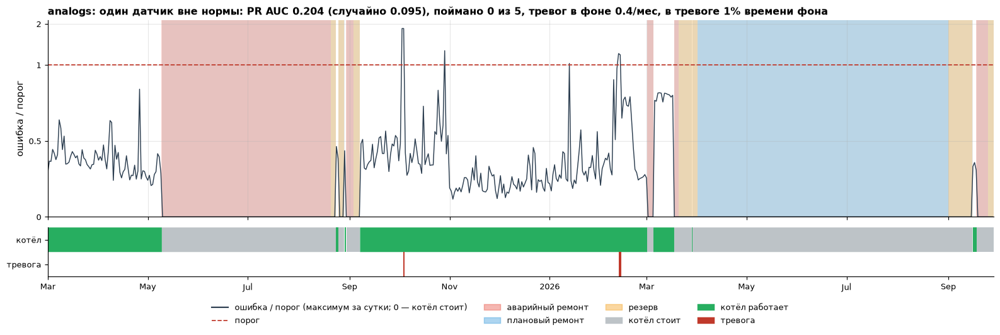


[2/40] Группа 2 · Индивидуальная · свои датчики · К-5; обучение: К-5
Группа 2 · К-5 · analogs
  Готово за 0.3 с; рассчитано 6177 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: кэш.
Группа 2 · К-5 · AAKR
  Готово за 5.3 мин; рассчитано 6177 ч; обучений: 17; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.233,0.094,0 из 5,0.000,0.000,0.000,0.9,0,6,0,5177.000,6177.000
analogs: несколько датчиков,0.154,0.094,0 из 5,0.000,0.000,0.000,0.9,0,6,0,5177.000,6177.000
analogs: медленный сдвиг (2 сут),0.375,0.094,2 из 5,0.400,0.400,0.400,4.2,2,3,0,5177.000,6177.000
AAKR: один датчик вне нормы,0.202,0.094,0 из 5,0.000,0.000,0.000,1.0,0,4,1,5177.000,6177.000
AAKR: несколько датчиков,0.113,0.094,0 из 5,0.000,0.000,0.000,1.2,0,5,0,5177.000,6177.000
AAKR: медленный сдвиг (2 сут),0.285,0.094,3 из 5,0.429,0.600,0.500,3.5,3,4,0,5177.000,6177.000



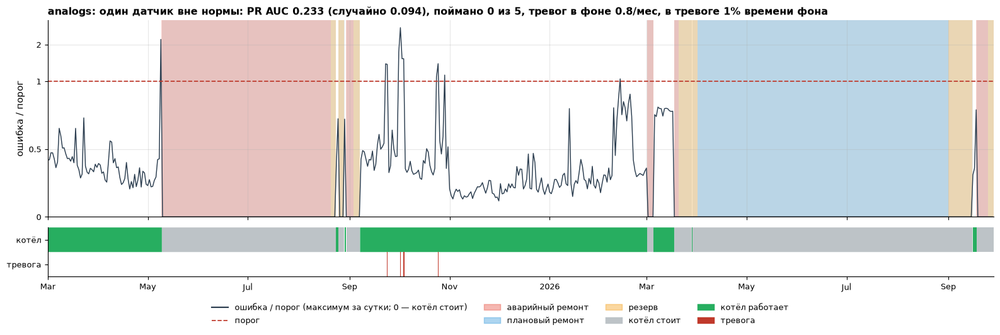


[3/40] Группа 2 · Индивидуальная · общие датчики · К-6; обучение: К-6
Группа 2 · К-6 · analogs
  Готово за 29.7 с; рассчитано 6249 ч; обучений: 21; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-6 · AAKR
  Готово за 5.2 мин; рассчитано 6249 ч; обучений: 21; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.175,0.254,2 из 9,0.222,0.222,0.222,3.3,2,7,2,3957.000,6249.000
analogs: несколько датчиков,0.182,0.254,1 из 9,0.125,0.111,0.118,5.4,1,7,0,3957.000,6249.000
analogs: медленный сдвиг (2 сут),0.260,0.254,0 из 9,0.000,0.000,0.000,6.2,0,1,0,3957.000,6249.000
AAKR: один датчик вне нормы,0.269,0.254,2 из 9,0.333,0.222,0.267,2.7,2,4,1,3957.000,6249.000
AAKR: несколько датчиков,0.233,0.254,1 из 9,0.400,0.111,0.174,2.7,2,3,0,3957.000,6249.000
AAKR: медленный сдвиг (2 сут),0.381,0.254,3 из 9,0.444,0.333,0.381,4.2,4,5,1,3957.000,6249.000



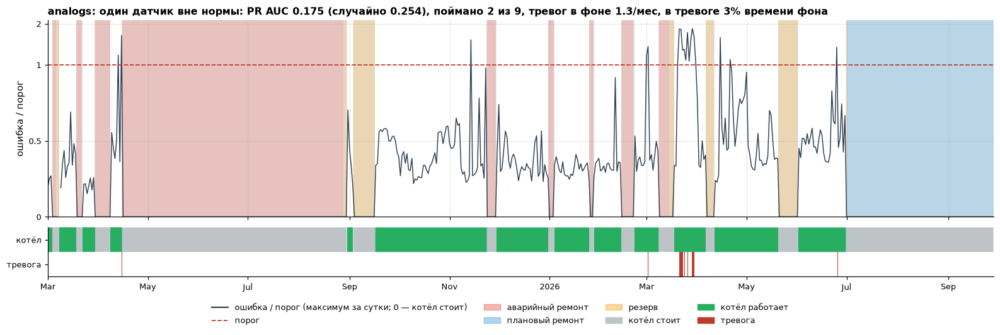


[4/40] Группа 2 · Индивидуальная · свои датчики · К-6; обучение: К-6
Группа 2 · К-6 · analogs
  Готово за 38.9 с; рассчитано 6249 ч; обучений: 21; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-6 · AAKR
  Готово за 6.1 мин; рассчитано 6249 ч; обучений: 21; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.199,0.254,2 из 9,0.286,0.222,0.250,3.5,2,5,1,3957.000,6249.000
analogs: несколько датчиков,0.213,0.254,2 из 9,0.333,0.222,0.267,4.9,3,6,1,3957.000,6249.000
analogs: медленный сдвиг (2 сут),0.279,0.254,0 из 9,0.000,0.000,0.000,6.2,0,1,0,3957.000,6249.000
AAKR: один датчик вне нормы,0.250,0.254,2 из 9,0.333,0.222,0.267,3.1,2,4,0,3957.000,6249.000
AAKR: несколько датчиков,0.243,0.254,1 из 9,0.286,0.111,0.160,3.5,2,5,1,3957.000,6249.000
AAKR: медленный сдвиг (2 сут),0.346,0.254,1 из 9,0.286,0.111,0.160,6.2,2,5,1,3957.000,6249.000



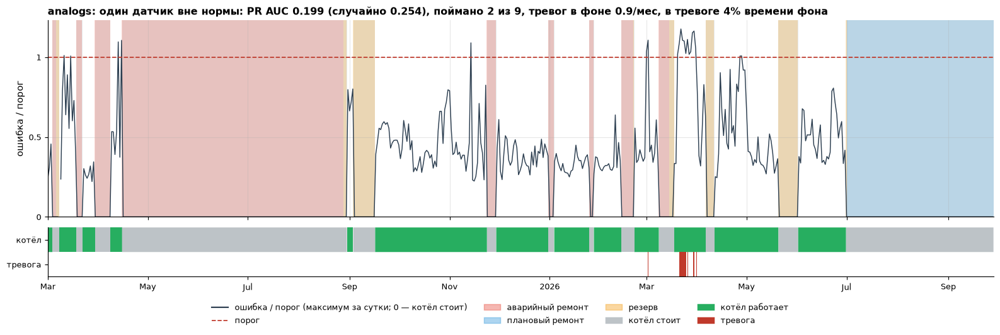


[5/40] Группа 2 · Индивидуальная · общие датчики · К-7; обучение: К-7
Группа 2 · К-7 · analogs
  Готово за 36.9 с; рассчитано 6449 ч; обучений: 25; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-7 · AAKR
  Готово за 5.4 мин; рассчитано 6449 ч; обучений: 25; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.283,0.246,1 из 8,0.231,0.125,0.162,12.0,3,10,1,3931.000,6449.000
analogs: несколько датчиков,0.295,0.246,1 из 8,0.375,0.125,0.188,11.9,3,5,1,3931.000,6449.000
analogs: медленный сдвиг (2 сут),0.276,0.246,3 из 8,0.353,0.375,0.364,23.2,6,11,2,3931.000,6449.000
AAKR: один датчик вне нормы,0.277,0.246,1 из 8,0.375,0.125,0.188,15.8,3,5,1,3931.000,6449.000
AAKR: несколько датчиков,0.290,0.246,2 из 8,0.625,0.250,0.357,13.6,5,3,2,3931.000,6449.000
AAKR: медленный сдвиг (2 сут),0.292,0.246,2 из 8,0.357,0.250,0.294,22.0,5,9,1,3931.000,6449.000



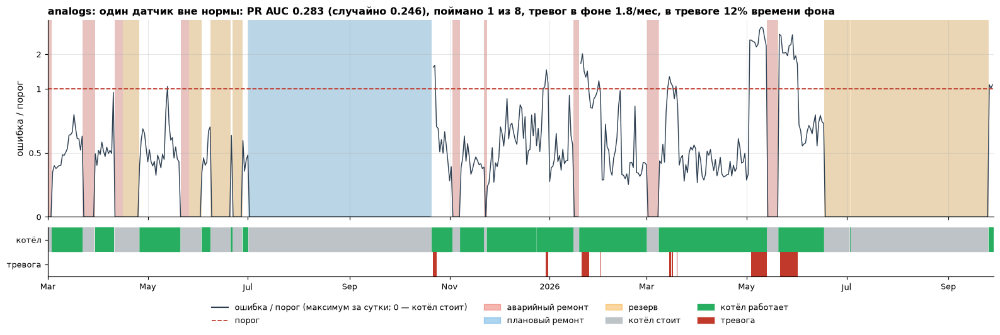


[6/40] Группа 2 · Индивидуальная · свои датчики · К-7; обучение: К-7
Группа 2 · К-7 · analogs
  Готово за 42.4 с; рассчитано 6449 ч; обучений: 25; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-7 · AAKR
  Готово за 6.0 мин; рассчитано 6449 ч; обучений: 25; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.281,0.246,2 из 8,0.400,0.250,0.308,11.2,4,6,1,3931.000,6449.000
analogs: несколько датчиков,0.295,0.246,1 из 8,0.273,0.125,0.171,12.8,3,8,0,3931.000,6449.000
analogs: медленный сдвиг (2 сут),0.289,0.246,4 из 8,0.370,0.500,0.426,29.3,10,17,4,3931.000,6449.000
AAKR: один датчик вне нормы,0.270,0.246,1 из 8,0.333,0.125,0.182,14.3,3,6,1,3931.000,6449.000
AAKR: несколько датчиков,0.296,0.246,2 из 8,0.571,0.250,0.348,13.6,4,3,1,3931.000,6449.000
AAKR: медленный сдвиг (2 сут),0.297,0.246,3 из 8,0.368,0.375,0.372,24.5,7,12,2,3931.000,6449.000



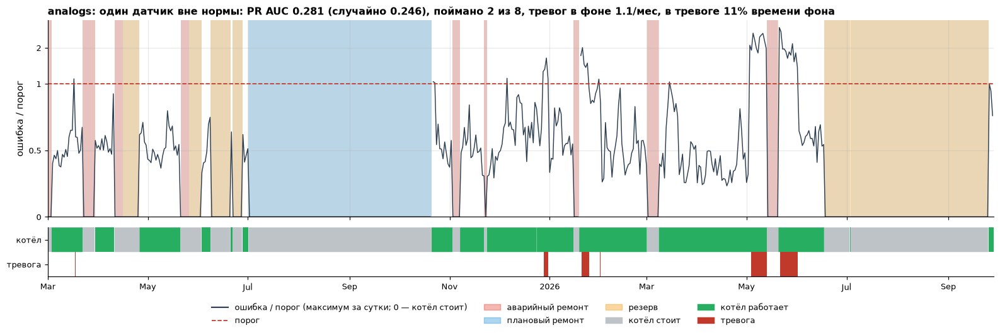


[7/40] Группа 2 · Общая модель · К-5; обучение: К-5, К-6, К-7
Группа 2 · К-5 · analogs
  Готово за 1.3 мин; рассчитано 6171 ч; обучений: 23; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-5 · AAKR
  Готово за 6.0 мин; рассчитано 6171 ч; обучений: 23; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.109,0.095,0 из 5,0.000,0.000,0.000,2.3,0,4,3,5171.000,6171.000
analogs: несколько датчиков,0.107,0.095,0 из 5,0.000,0.000,0.000,0.7,0,2,1,5171.000,6171.000
analogs: медленный сдвиг (2 сут),0.129,0.095,0 из 5,0.000,0.000,0.000,2.2,0,2,0,5171.000,6171.000
AAKR: один датчик вне нормы,0.129,0.095,0 из 5,0.000,0.000,0.000,2.2,0,3,0,5171.000,6171.000
AAKR: несколько датчиков,0.120,0.095,0 из 5,0.000,0.000,0.000,1.0,0,3,2,5171.000,6171.000
AAKR: медленный сдвиг (2 сут),0.197,0.095,0 из 5,0.000,0.000,0.000,1.5,0,1,0,5171.000,6171.000



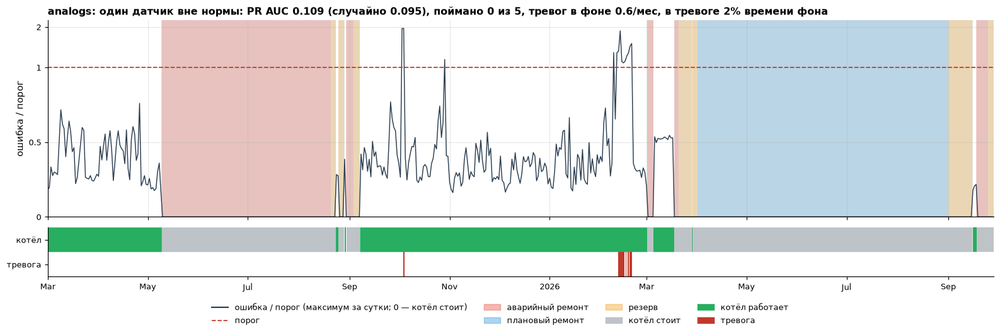


[8/40] Группа 2 · Общая модель · К-6; обучение: К-5, К-6, К-7
Группа 2 · К-6 · analogs
  Готово за 37.9 с; рассчитано 6249 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-6 · AAKR
  Готово за 1.1 мин; рассчитано 6249 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.225,0.254,2 из 9,0.400,0.222,0.286,0.6,2,3,0,3957.000,6249.000
analogs: несколько датчиков,0.241,0.254,2 из 9,0.500,0.222,0.308,0.5,2,2,0,3957.000,6249.000
analogs: медленный сдвиг (2 сут),0.217,0.254,1 из 9,0.250,0.111,0.154,2.4,1,3,0,3957.000,6249.000
AAKR: один датчик вне нормы,0.283,0.254,1 из 9,1.000,0.111,0.200,0.0,1,0,0,3957.000,6249.000
AAKR: несколько датчиков,0.280,0.254,1 из 9,0.333,0.111,0.167,2.2,1,2,0,3957.000,6249.000
AAKR: медленный сдвиг (2 сут),0.350,0.254,2 из 9,0.500,0.222,0.308,1.4,2,2,1,3957.000,6249.000



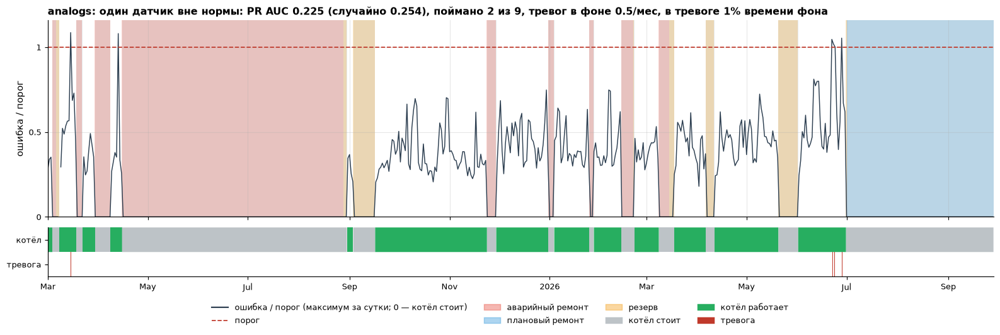


[9/40] Группа 2 · Общая модель · К-7; обучение: К-5, К-6, К-7
Группа 2 · К-7 · analogs
  Готово за 37.7 с; рассчитано 6449 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-7 · AAKR
  Готово за 1.1 мин; рассчитано 6449 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.288,0.246,1 из 8,0.429,0.125,0.194,0.7,3,4,1,3931.000,6449.000
analogs: несколько датчиков,0.280,0.246,1 из 8,0.125,0.125,0.125,4.4,1,7,0,3931.000,6449.000
analogs: медленный сдвиг (2 сут),0.318,0.246,1 из 8,0.429,0.125,0.194,7.1,3,4,1,3931.000,6449.000
AAKR: один датчик вне нормы,0.285,0.246,1 из 8,0.600,0.125,0.207,7.0,3,2,1,3931.000,6449.000
AAKR: несколько датчиков,0.296,0.246,1 из 8,0.500,0.125,0.200,8.0,3,3,1,3931.000,6449.000
AAKR: медленный сдвиг (2 сут),0.298,0.246,1 из 8,0.600,0.125,0.207,7.8,3,2,1,3931.000,6449.000



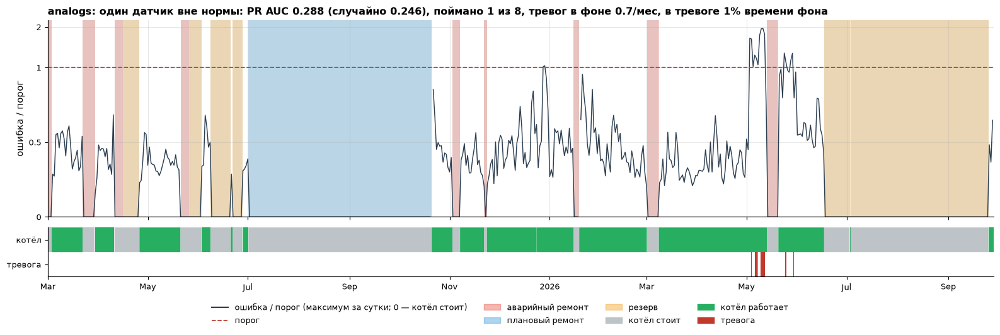


[10/40] Группа 2 · Перенос с другого котла · К-5; обучение: К-6
Группа 2 · К-5 · analogs
  Готово за 15.1 с; рассчитано 6171 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-5 · AAKR
  Готово за 1.2 мин; рассчитано 6171 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.088,0.095,5 из 5,0.455,1.000,0.625,99.9,5,6,0,5171.000,6171.000
analogs: несколько датчиков,0.187,0.095,5 из 5,0.455,1.000,0.625,99.9,5,6,0,5171.000,6171.000
analogs: медленный сдвиг (2 сут),0.236,0.095,4 из 5,0.400,0.800,0.533,99.5,4,6,0,5171.000,6171.000
AAKR: один датчик вне нормы,0.072,0.095,5 из 5,0.455,1.000,0.625,99.9,5,6,0,5171.000,6171.000
AAKR: несколько датчиков,0.130,0.095,5 из 5,0.455,1.000,0.625,99.9,5,6,0,5171.000,6171.000
AAKR: медленный сдвиг (2 сут),0.353,0.095,5 из 5,0.455,1.000,0.625,99.9,5,6,0,5171.000,6171.000



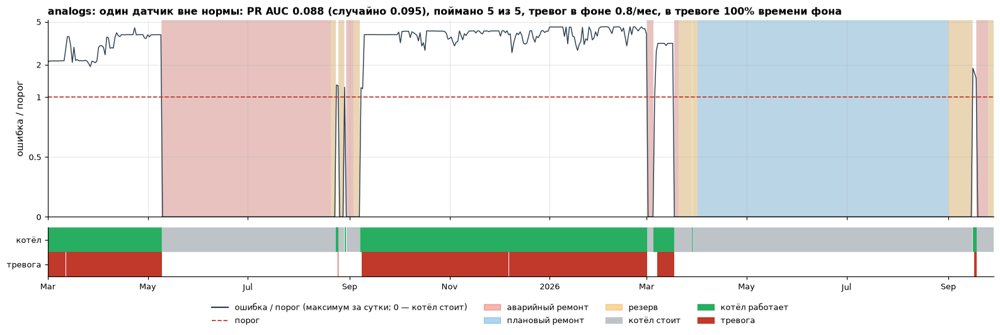


[11/40] Группа 2 · Перенос с другого котла · К-5; обучение: К-7
Группа 2 · К-5 · analogs
  Готово за 15.8 с; рассчитано 6171 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-5 · AAKR
  Готово за 1.2 мин; рассчитано 6171 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.097,0.095,4 из 5,0.111,0.800,0.195,86.2,4,32,1,5171.000,6171.000
analogs: несколько датчиков,0.083,0.095,5 из 5,0.455,1.000,0.625,99.9,5,6,0,5171.000,6171.000
analogs: медленный сдвиг (2 сут),0.114,0.095,5 из 5,0.455,1.000,0.625,99.9,5,6,0,5171.000,6171.000
AAKR: один датчик вне нормы,0.201,0.095,5 из 5,0.455,1.000,0.625,99.9,5,6,0,5171.000,6171.000
AAKR: несколько датчиков,0.096,0.095,5 из 5,0.455,1.000,0.625,99.9,5,6,0,5171.000,6171.000
AAKR: медленный сдвиг (2 сут),0.380,0.095,5 из 5,0.455,1.000,0.625,99.9,5,6,0,5171.000,6171.000



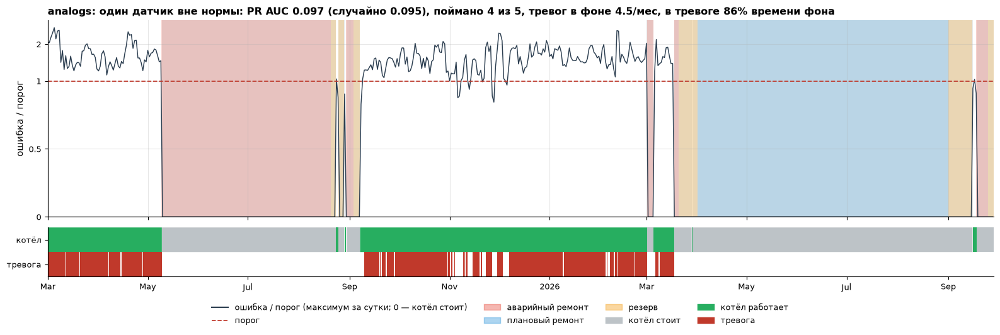


[12/40] Группа 2 · Перенос с другого котла · К-6; обучение: К-5
Группа 2 · К-6 · analogs
  Готово за 17.0 с; рассчитано 6249 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-6 · AAKR
  Готово за 1.2 мин; рассчитано 6249 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.295,0.254,7 из 9,0.389,0.778,0.519,15.0,14,22,7,3957.000,6249.000
analogs: несколько датчиков,0.358,0.254,7 из 9,0.268,0.778,0.398,36.1,15,41,5,3957.000,6249.000
analogs: медленный сдвиг (2 сут),0.290,0.254,9 из 9,0.481,1.000,0.650,92.2,13,14,2,3957.000,6249.000
AAKR: один датчик вне нормы,0.431,0.254,6 из 9,0.409,0.667,0.507,35.0,9,13,5,3957.000,6249.000
AAKR: несколько датчиков,0.383,0.254,9 из 9,0.444,1.000,0.615,90.4,16,20,4,3957.000,6249.000
AAKR: медленный сдвиг (2 сут),0.184,0.254,9 из 9,0.565,1.000,0.722,100.0,13,10,2,3957.000,6249.000



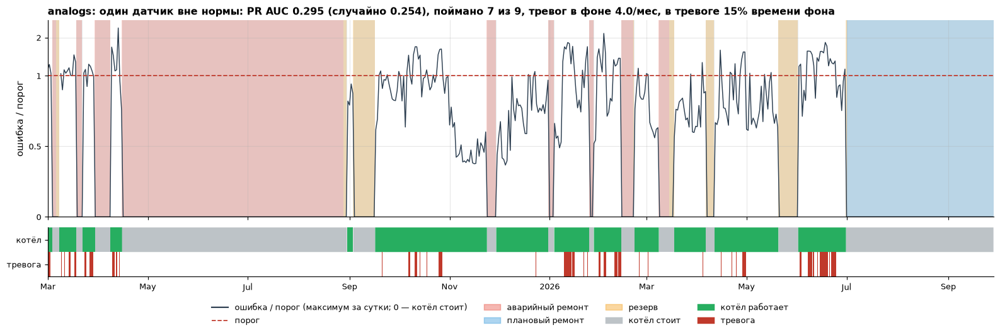


[13/40] Группа 2 · Перенос с другого котла · К-6; обучение: К-7
Группа 2 · К-6 · analogs
  Готово за 16.3 с; рассчитано 6249 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-6 · AAKR
  Готово за 1.2 мин; рассчитано 6249 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.363,0.254,9 из 9,0.246,1.000,0.395,67.2,17,52,2,3957.000,6249.000
analogs: несколько датчиков,0.388,0.254,9 из 9,0.500,1.000,0.667,98.1,13,13,2,3957.000,6249.000
analogs: медленный сдвиг (2 сут),0.558,0.254,9 из 9,0.565,1.000,0.722,100.0,13,10,2,3957.000,6249.000
AAKR: один датчик вне нормы,0.219,0.254,9 из 9,0.565,1.000,0.722,100.0,13,10,2,3957.000,6249.000
AAKR: несколько датчиков,0.330,0.254,9 из 9,0.565,1.000,0.722,100.0,13,10,2,3957.000,6249.000
AAKR: медленный сдвиг (2 сут),0.338,0.254,9 из 9,0.565,1.000,0.722,100.0,13,10,2,3957.000,6249.000



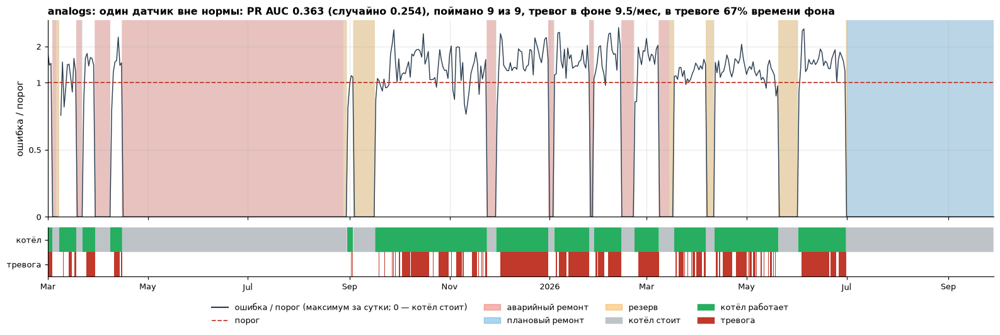


[14/40] Группа 2 · Перенос с другого котла · К-7; обучение: К-5
Группа 2 · К-7 · analogs
  Готово за 16.9 с; рассчитано 6449 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-7 · AAKR
  Готово за 1.2 мин; рассчитано 6449 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.401,0.246,6 из 8,0.275,0.750,0.402,28.0,14,37,4,3931.000,6449.000
analogs: несколько датчиков,0.410,0.246,7 из 8,0.367,0.875,0.517,62.6,18,31,4,3931.000,6449.000
analogs: медленный сдвиг (2 сут),0.332,0.246,8 из 8,0.548,1.000,0.708,100.0,17,14,2,3931.000,6449.000
AAKR: один датчик вне нормы,0.319,0.246,8 из 8,0.472,1.000,0.642,43.8,17,19,3,3931.000,6449.000
AAKR: несколько датчиков,0.339,0.246,8 из 8,0.444,1.000,0.615,72.8,16,20,5,3931.000,6449.000
AAKR: медленный сдвиг (2 сут),0.277,0.246,8 из 8,0.533,1.000,0.696,100.0,16,14,1,3931.000,6449.000



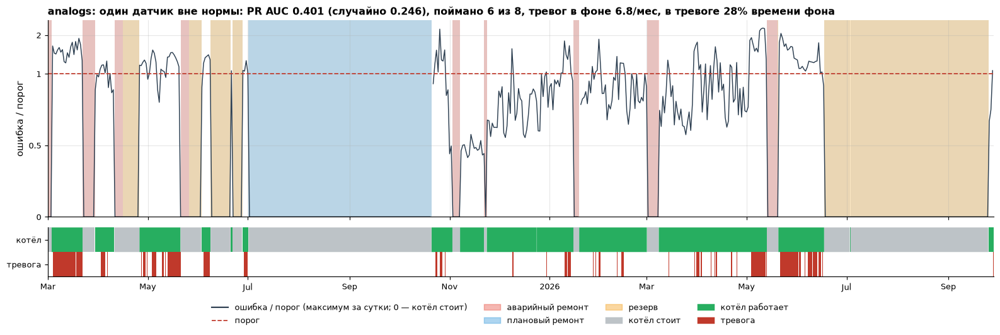


[15/40] Группа 2 · Перенос с другого котла · К-7; обучение: К-6
Группа 2 · К-7 · analogs
  Готово за 19.3 с; рассчитано 6449 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 2 · К-7 · AAKR
  Готово за 1.4 мин; рассчитано 6449 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.255,0.246,8 из 8,0.321,1.000,0.486,34.1,17,36,11,3931.000,6449.000
analogs: несколько датчиков,0.277,0.246,8 из 8,0.365,1.000,0.535,87.2,19,33,5,3931.000,6449.000
analogs: медленный сдвиг (2 сут),0.345,0.246,4 из 8,0.273,0.500,0.353,42.2,9,24,4,3931.000,6449.000
AAKR: один датчик вне нормы,0.255,0.246,7 из 8,0.255,0.875,0.395,38.5,13,38,11,3931.000,6449.000
AAKR: несколько датчиков,0.258,0.246,8 из 8,0.533,1.000,0.696,100.0,16,14,1,3931.000,6449.000
AAKR: медленный сдвиг (2 сут),0.254,0.246,8 из 8,0.533,1.000,0.696,95.4,16,14,4,3931.000,6449.000



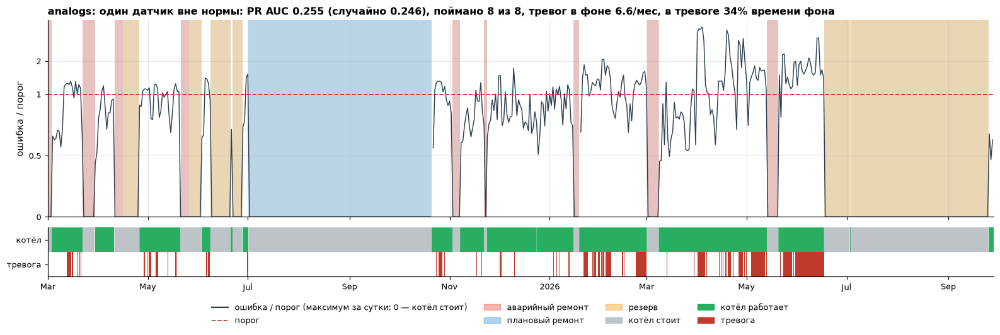


[16/40] Группа 1 · Индивидуальная · общие датчики · К-1; обучение: К-1
Группа 1 · К-1 · analogs
  Готово за 0.4 с; рассчитано 2841 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: кэш.
Группа 1 · К-1 · AAKR
  Готово за 2.9 мин; рассчитано 2841 ч; обучений: 13; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.107,0.135,0 из 4,0.000,0.000,0.000,4.9,0,6,0,2295.000,2841.000
analogs: несколько датчиков,0.096,0.135,2 из 4,0.200,0.500,0.286,10.0,1,4,1,2295.000,2841.000
analogs: медленный сдвиг (2 сут),0.094,0.135,3 из 4,0.273,0.750,0.400,33.4,3,8,0,2295.000,2841.000
AAKR: один датчик вне нормы,0.094,0.135,2 из 4,0.400,0.500,0.444,20.7,2,3,0,2295.000,2841.000
AAKR: несколько датчиков,0.095,0.135,2 из 4,0.500,0.500,0.500,18.8,2,2,1,2295.000,2841.000
AAKR: медленный сдвиг (2 сут),0.086,0.135,3 из 4,0.214,0.750,0.333,46.4,3,11,0,2295.000,2841.000



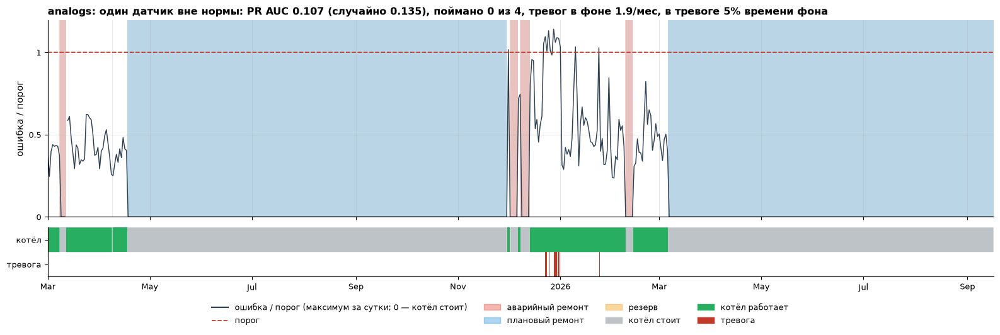


[17/40] Группа 1 · Индивидуальная · свои датчики · К-1; обучение: К-1
Группа 1 · К-1 · analogs
  Готово за 30.0 с; рассчитано 2842 ч; обучений: 13; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-1 · AAKR
  Готово за 5.2 мин; рассчитано 2842 ч; обучений: 13; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.197,0.135,0 из 4,0.000,0.000,0.000,0.1,0,1,0,2295.000,2842.000
analogs: несколько датчиков,0.198,0.135,0 из 4,0.000,0.000,0.000,0.1,0,1,0,2295.000,2842.000
analogs: медленный сдвиг (2 сут),0.096,0.135,2 из 4,0.222,0.500,0.308,27.2,2,7,0,2295.000,2842.000
AAKR: один датчик вне нормы,0.133,0.135,0 из 4,0.000,0.000,0.000,0.1,0,1,0,2295.000,2842.000
AAKR: несколько датчиков,0.135,0.135,0 из 4,0.000,0.000,0.000,0.1,0,1,0,2295.000,2842.000
AAKR: медленный сдвиг (2 сут),0.087,0.135,3 из 4,0.300,0.750,0.429,36.4,3,7,0,2295.000,2842.000



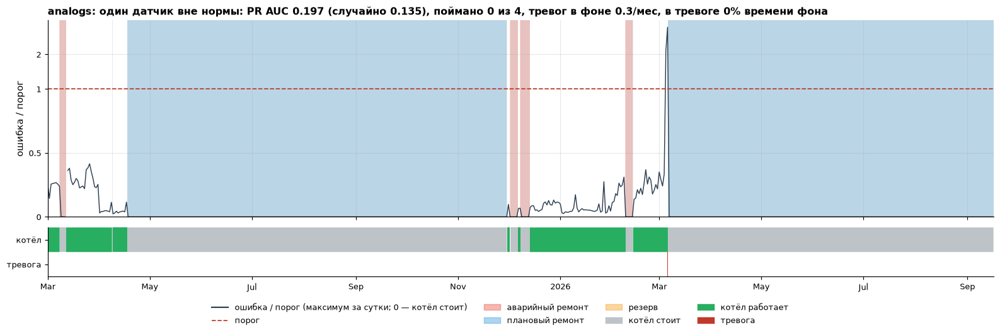


[18/40] Группа 1 · Индивидуальная · общие датчики · К-2; обучение: К-2
Группа 1 · К-2 · analogs
  Готово за 27.5 с; рассчитано 10668 ч; обучений: 25; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-2 · AAKR
  Готово за 4.7 мин; рассчитано 10668 ч; обучений: 25; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.055,0.049,0 из 3,0.000,0.000,0.000,0.4,0,5,0,9391.000,10668.000
analogs: несколько датчиков,0.042,0.049,0 из 3,0.000,0.000,0.000,0.2,0,3,0,9391.000,10668.000
analogs: медленный сдвиг (2 сут),0.042,0.049,1 из 3,0.067,0.333,0.111,7.1,1,14,2,9391.000,10668.000
AAKR: один датчик вне нормы,0.129,0.049,1 из 3,0.400,0.333,0.364,0.4,2,3,0,9391.000,10668.000
AAKR: несколько датчиков,0.145,0.049,1 из 3,0.167,0.333,0.222,0.5,1,5,0,9391.000,10668.000
AAKR: медленный сдвиг (2 сут),0.104,0.049,1 из 3,0.111,0.333,0.167,3.2,1,8,0,9391.000,10668.000



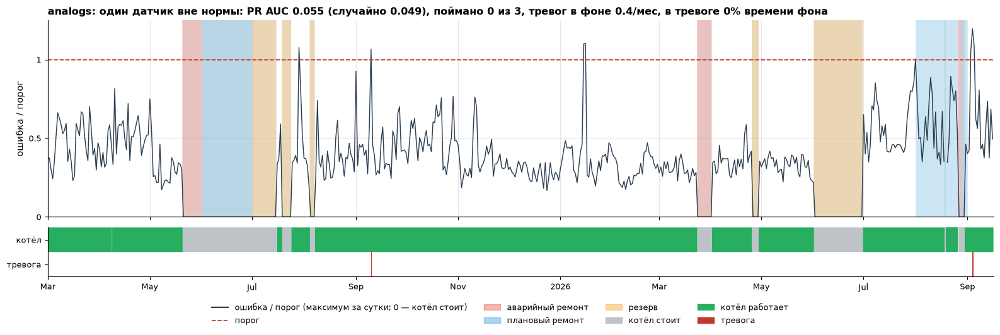


[19/40] Группа 1 · Индивидуальная · свои датчики · К-2; обучение: К-2
Группа 1 · К-2 · analogs
  Готово за 45.8 с; рассчитано 10519 ч; обучений: 25; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-2 · AAKR
  Готово за 9.4 мин; рассчитано 10519 ч; обучений: 25; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.033,0.049,0 из 3,0.000,0.000,0.000,3.9,0,14,0,9248.000,10519.000
analogs: несколько датчиков,0.034,0.049,0 из 3,0.000,0.000,0.000,3.3,0,11,0,9248.000,10519.000
analogs: медленный сдвиг (2 сут),0.034,0.049,1 из 3,0.023,0.333,0.043,14.2,1,43,1,9248.000,10519.000
AAKR: один датчик вне нормы,0.048,0.049,1 из 3,0.083,0.333,0.133,11.5,1,11,0,9248.000,10519.000
AAKR: несколько датчиков,0.049,0.049,1 из 3,0.091,0.333,0.143,11.4,1,10,0,9248.000,10519.000
AAKR: медленный сдвиг (2 сут),0.062,0.049,1 из 3,0.091,0.333,0.143,16.6,2,20,0,9248.000,10519.000



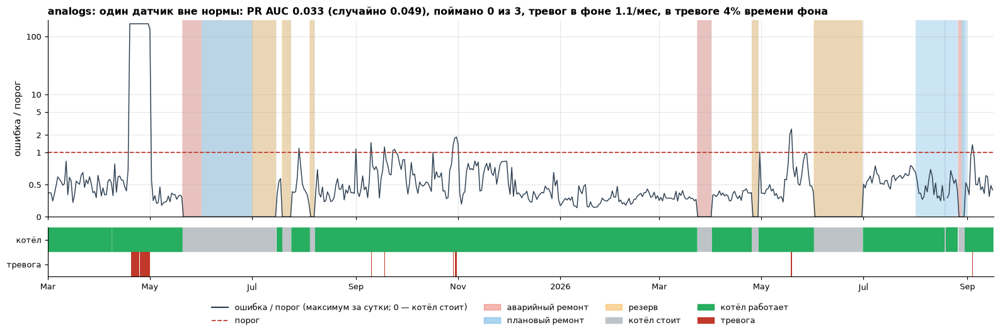


[20/40] Группа 1 · Индивидуальная · общие датчики · К-3; обучение: К-3
Группа 1 · К-3 · analogs
  Готово за 29.9 с; рассчитано 9932 ч; обучений: 23; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-3 · AAKR
  Готово за 5.6 мин; рассчитано 9932 ч; обучений: 23; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.316,0.212,2 из 8,0.400,0.250,0.308,2.6,4,6,12,4094.000,9932.000
analogs: несколько датчиков,0.278,0.212,2 из 8,0.400,0.250,0.308,3.1,4,6,11,4094.000,9932.000
analogs: медленный сдвиг (2 сут),0.286,0.212,3 из 8,0.227,0.375,0.283,13.0,5,17,12,4094.000,9932.000
AAKR: один датчик вне нормы,0.174,0.212,1 из 8,0.143,0.125,0.133,1.5,1,6,8,4094.000,9932.000
AAKR: несколько датчиков,0.162,0.212,1 из 8,0.125,0.125,0.125,1.8,1,7,8,4094.000,9932.000
AAKR: медленный сдвиг (2 сут),0.144,0.212,1 из 8,0.077,0.125,0.095,7.5,1,12,10,4094.000,9932.000



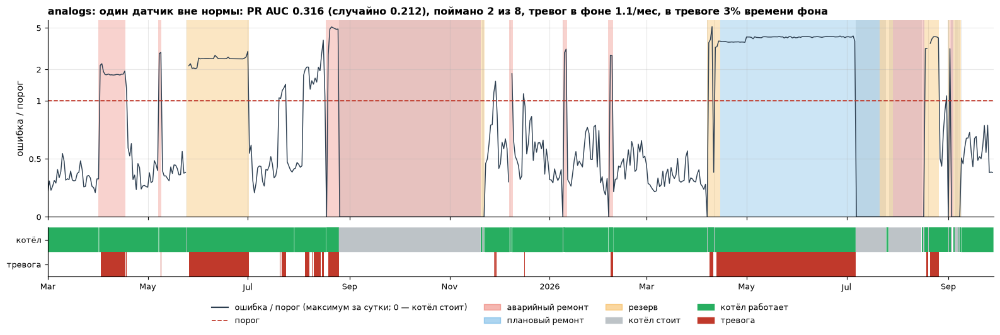


[21/40] Группа 1 · Индивидуальная · свои датчики · К-3; обучение: К-3
Группа 1 · К-3 · analogs
  Готово за 43.2 с; рассчитано 9930 ч; обучений: 23; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-3 · AAKR
  Готово за 8.0 мин; рассчитано 9930 ч; обучений: 23; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.256,0.212,2 из 8,0.364,0.250,0.296,4.3,4,7,11,4093.000,9930.000
analogs: несколько датчиков,0.256,0.212,2 из 8,0.444,0.250,0.320,2.9,4,5,12,4093.000,9930.000
analogs: медленный сдвиг (2 сут),0.245,0.212,3 из 8,0.217,0.375,0.275,14.7,5,18,11,4093.000,9930.000
AAKR: один датчик вне нормы,0.162,0.212,1 из 8,0.167,0.125,0.143,1.4,1,5,8,4093.000,9930.000
AAKR: несколько датчиков,0.161,0.212,1 из 8,0.125,0.125,0.125,1.8,1,7,9,4093.000,9930.000
AAKR: медленный сдвиг (2 сут),0.145,0.212,1 из 8,0.105,0.125,0.114,15.7,2,17,10,4093.000,9930.000



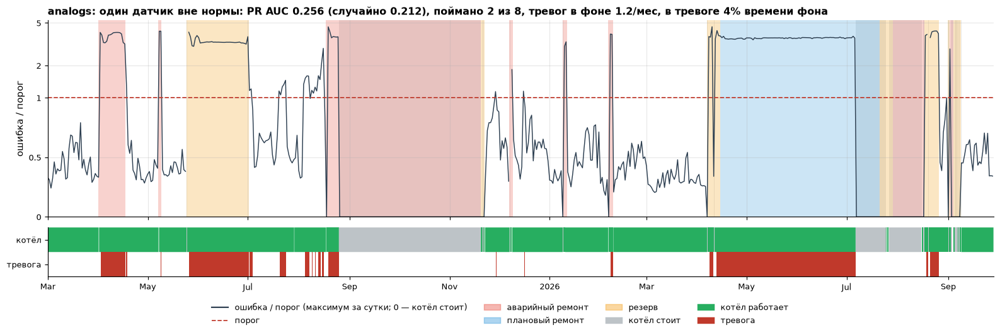


[22/40] Группа 1 · Индивидуальная · общие датчики · К-4; обучение: К-4
Группа 1 · К-4 · analogs
  Готово за 30.7 с; рассчитано 7816 ч; обучений: 22; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-4 · AAKR
  Готово за 4.6 мин; рассчитано 7816 ч; обучений: 22; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.093,0.115,0 из 5,0.000,0.000,0.000,5.7,0,9,0,6295.000,7816.000
analogs: несколько датчиков,0.097,0.115,0 из 5,0.000,0.000,0.000,4.8,0,11,0,6295.000,7816.000
analogs: медленный сдвиг (2 сут),0.098,0.115,1 из 5,0.143,0.200,0.167,11.7,1,6,0,6295.000,7816.000
AAKR: один датчик вне нормы,0.116,0.115,0 из 5,0.000,0.000,0.000,10.2,0,3,0,6295.000,7816.000
AAKR: несколько датчиков,0.117,0.115,0 из 5,0.000,0.000,0.000,10.4,0,4,0,6295.000,7816.000
AAKR: медленный сдвиг (2 сут),0.132,0.115,1 из 5,0.400,0.200,0.267,10.3,2,3,0,6295.000,7816.000



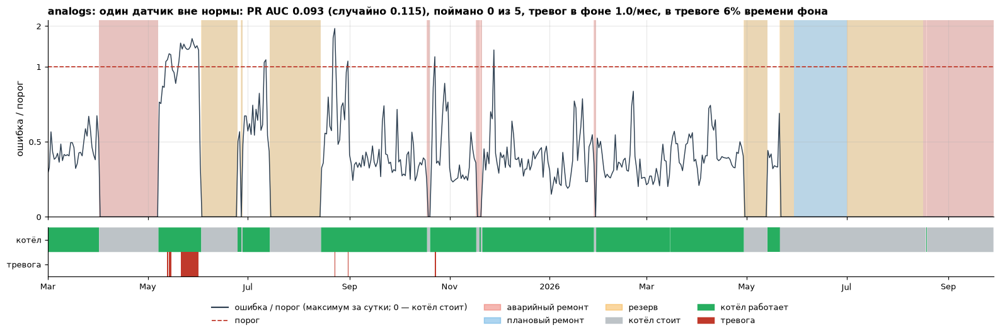


[23/40] Группа 1 · Индивидуальная · свои датчики · К-4; обучение: К-4
Группа 1 · К-4 · analogs
  Готово за 38.3 с; рассчитано 7814 ч; обучений: 22; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-4 · AAKR
  Готово за 6.1 мин; рассчитано 7814 ч; обучений: 22; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.089,0.115,0 из 5,0.000,0.000,0.000,5.2,0,8,0,6294.000,7814.000
analogs: несколько датчиков,0.082,0.115,0 из 5,0.000,0.000,0.000,4.9,0,10,0,6294.000,7814.000
analogs: медленный сдвиг (2 сут),0.103,0.115,0 из 5,0.000,0.000,0.000,9.0,0,1,0,6294.000,7814.000
AAKR: один датчик вне нормы,0.109,0.115,0 из 5,0.000,0.000,0.000,10.2,0,8,0,6294.000,7814.000
AAKR: несколько датчиков,0.096,0.115,0 из 5,0.000,0.000,0.000,10.8,0,9,0,6294.000,7814.000
AAKR: медленный сдвиг (2 сут),0.113,0.115,1 из 5,0.167,0.200,0.182,11.2,1,5,0,6294.000,7814.000



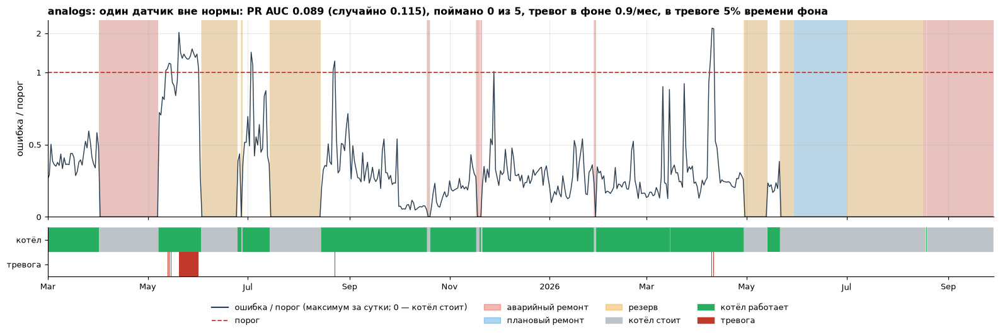


[24/40] Группа 1 · Общая модель · К-1; обучение: К-1, К-2, К-3, К-4
Группа 1 · К-1 · analogs
  Готово за 1.4 мин; рассчитано 2841 ч; обучений: 26; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-1 · AAKR
  Готово за 6.8 мин; рассчитано 2841 ч; обучений: 26; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.100,0.135,0 из 4,0.000,0.000,0.000,0.2,0,1,0,2295.000,2841.000
analogs: несколько датчиков,0.109,0.135,0 из 4,0.000,0.000,0.000,0.3,0,1,0,2295.000,2841.000
analogs: медленный сдвиг (2 сут),0.095,0.135,0 из 4,0.000,0.000,0.000,5.2,0,3,0,2295.000,2841.000
AAKR: один датчик вне нормы,0.142,0.135,0 из 4,—,0.000,—,0.0,0,0,0,2295.000,2841.000
AAKR: несколько датчиков,0.109,0.135,0 из 4,—,0.000,—,0.0,0,0,0,2295.000,2841.000
AAKR: медленный сдвиг (2 сут),0.095,0.135,0 из 4,—,0.000,—,0.0,0,0,0,2295.000,2841.000



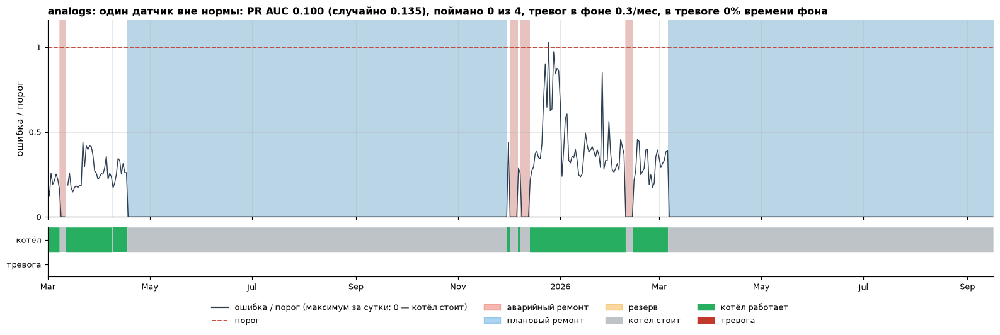


[25/40] Группа 1 · Общая модель · К-2; обучение: К-1, К-2, К-3, К-4
Группа 1 · К-2 · analogs
  Готово за 47.1 с; рассчитано 10668 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-2 · AAKR
  Готово за 1.6 мин; рассчитано 10668 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.039,0.049,0 из 3,—,0.000,—,0.0,0,0,0,9391.000,10668.000
analogs: несколько датчиков,0.037,0.049,0 из 3,0.000,0.000,0.000,0.2,0,1,0,9391.000,10668.000
analogs: медленный сдвиг (2 сут),0.038,0.049,0 из 3,—,0.000,—,0.0,0,0,0,9391.000,10668.000
AAKR: один датчик вне нормы,0.052,0.049,1 из 3,0.167,0.333,0.222,1.2,1,5,1,9391.000,10668.000
AAKR: несколько датчиков,0.066,0.049,1 из 3,0.200,0.333,0.250,1.1,1,4,0,9391.000,10668.000
AAKR: медленный сдвиг (2 сут),0.035,0.049,0 из 3,0.000,0.000,0.000,0.5,0,2,0,9391.000,10668.000



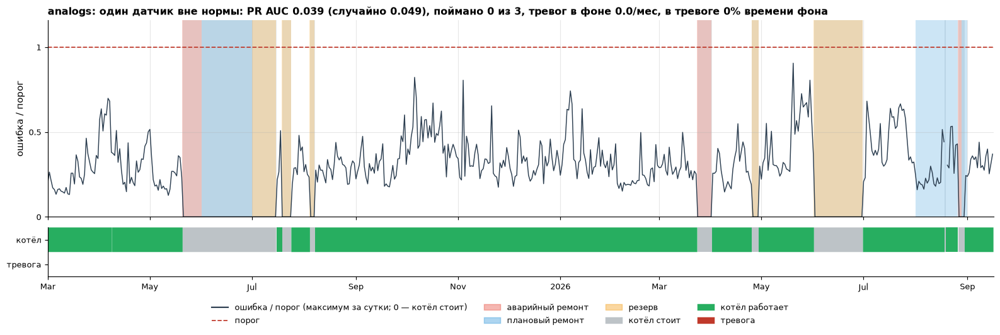


[26/40] Группа 1 · Общая модель · К-3; обучение: К-1, К-2, К-3, К-4
Группа 1 · К-3 · analogs
  Готово за 47.5 с; рассчитано 9932 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-3 · AAKR
  Готово за 1.8 мин; рассчитано 9932 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.192,0.212,1 из 8,0.250,0.125,0.167,0.3,1,3,8,4094.000,9932.000
analogs: несколько датчиков,0.204,0.212,2 из 8,0.500,0.250,0.333,0.4,3,3,8,4094.000,9932.000
analogs: медленный сдвиг (2 сут),0.175,0.212,1 из 8,0.091,0.125,0.105,4.5,1,10,9,4094.000,9932.000
AAKR: один датчик вне нормы,0.209,0.212,1 из 8,0.167,0.125,0.143,1.1,1,5,8,4094.000,9932.000
AAKR: несколько датчиков,0.198,0.212,1 из 8,0.222,0.125,0.160,1.4,2,7,8,4094.000,9932.000
AAKR: медленный сдвиг (2 сут),0.180,0.212,1 из 8,0.100,0.125,0.111,6.1,1,9,9,4094.000,9932.000



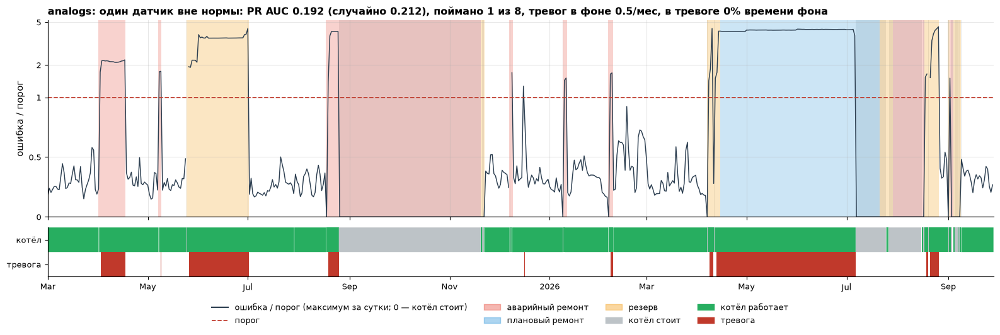


[27/40] Группа 1 · Общая модель · К-4; обучение: К-1, К-2, К-3, К-4
Группа 1 · К-4 · analogs
  Готово за 46.4 с; рассчитано 7816 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-4 · AAKR
  Готово за 1.4 мин; рассчитано 7816 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.102,0.115,0 из 5,0.000,0.000,0.000,1.7,0,4,0,6295.000,7816.000
analogs: несколько датчиков,0.102,0.115,0 из 5,0.000,0.000,0.000,1.3,0,1,0,6295.000,7816.000
analogs: медленный сдвиг (2 сут),0.107,0.115,0 из 5,0.000,0.000,0.000,1.8,0,2,0,6295.000,7816.000
AAKR: один датчик вне нормы,0.095,0.115,0 из 5,0.000,0.000,0.000,9.3,0,2,0,6295.000,7816.000
AAKR: несколько датчиков,0.096,0.115,0 из 5,0.000,0.000,0.000,9.3,0,2,0,6295.000,7816.000
AAKR: медленный сдвиг (2 сут),0.088,0.115,0 из 5,0.000,0.000,0.000,9.0,0,1,0,6295.000,7816.000



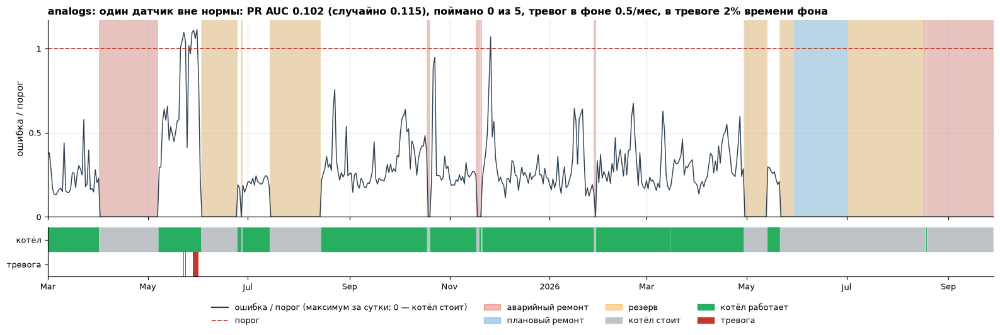


[28/40] Группа 1 · Перенос с другого котла · К-1; обучение: К-2
Группа 1 · К-1 · analogs
  Готово за 18.1 с; рассчитано 2841 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-1 · AAKR
  Готово за 39.1 с; рассчитано 2841 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.371,0.135,2 из 4,0.185,0.500,0.270,16.6,5,22,1,2295.000,2841.000
analogs: несколько датчиков,0.260,0.135,3 из 4,0.143,0.750,0.240,54.8,4,24,0,2295.000,2841.000
analogs: медленный сдвиг (2 сут),0.434,0.135,4 из 4,0.385,1.000,0.556,97.3,5,8,1,2295.000,2841.000
AAKR: один датчик вне нормы,0.158,0.135,2 из 4,0.333,0.500,0.400,56.7,3,6,1,2295.000,2841.000
AAKR: несколько датчиков,0.194,0.135,4 из 4,0.250,1.000,0.400,70.2,4,12,2,2295.000,2841.000
AAKR: медленный сдвиг (2 сут),0.113,0.135,4 из 4,0.417,1.000,0.588,99.9,5,7,0,2295.000,2841.000



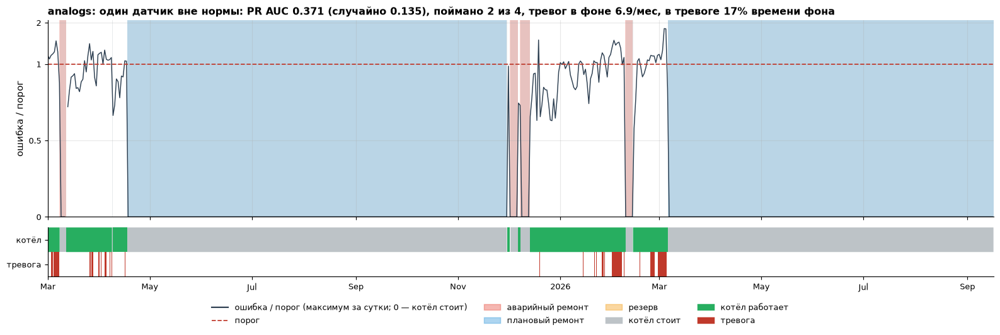


[29/40] Группа 1 · Перенос с другого котла · К-1; обучение: К-3
Группа 1 · К-1 · analogs
  Готово за 17.2 с; рассчитано 2841 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-1 · AAKR
  Готово за 38.9 с; рассчитано 2841 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.111,0.135,4 из 4,0.292,1.000,0.452,77.2,7,17,0,2295.000,2841.000
analogs: несколько датчиков,0.121,0.135,4 из 4,0.235,1.000,0.381,86.5,4,13,0,2295.000,2841.000
analogs: медленный сдвиг (2 сут),0.121,0.135,4 из 4,0.417,1.000,0.588,99.9,5,7,0,2295.000,2841.000
AAKR: один датчик вне нормы,0.114,0.135,2 из 4,0.200,0.500,0.286,16.4,2,8,0,2295.000,2841.000
AAKR: несколько датчиков,0.104,0.135,4 из 4,0.312,1.000,0.476,95.3,5,11,0,2295.000,2841.000
AAKR: медленный сдвиг (2 сут),0.122,0.135,4 из 4,0.417,1.000,0.588,99.9,5,7,0,2295.000,2841.000



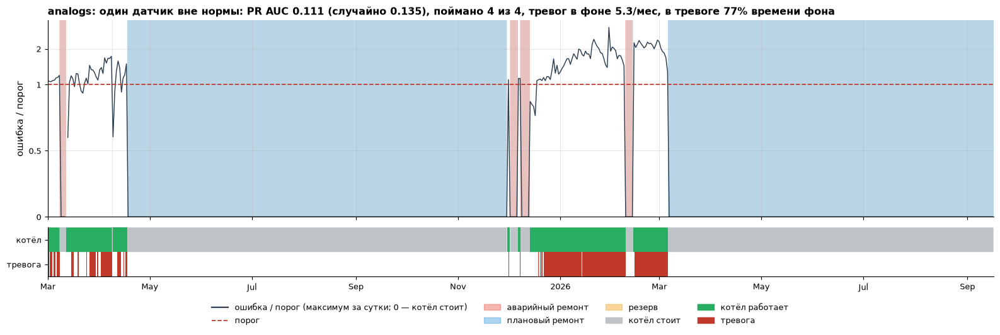


[30/40] Группа 1 · Перенос с другого котла · К-1; обучение: К-4
Группа 1 · К-1 · analogs
  Готово за 17.5 с; рассчитано 2841 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-1 · AAKR
  Готово за 38.6 с; рассчитано 2841 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.113,0.135,4 из 4,0.353,1.000,0.522,94.2,6,11,0,2295.000,2841.000
analogs: несколько датчиков,0.155,0.135,4 из 4,0.385,1.000,0.556,95.7,5,8,0,2295.000,2841.000
analogs: медленный сдвиг (2 сут),0.104,0.135,4 из 4,0.417,1.000,0.588,96.9,5,7,0,2295.000,2841.000
AAKR: один датчик вне нормы,0.105,0.135,4 из 4,0.417,1.000,0.588,99.9,5,7,0,2295.000,2841.000
AAKR: несколько датчиков,0.116,0.135,4 из 4,0.417,1.000,0.588,99.9,5,7,0,2295.000,2841.000
AAKR: медленный сдвиг (2 сут),0.115,0.135,4 из 4,0.417,1.000,0.588,99.9,5,7,0,2295.000,2841.000



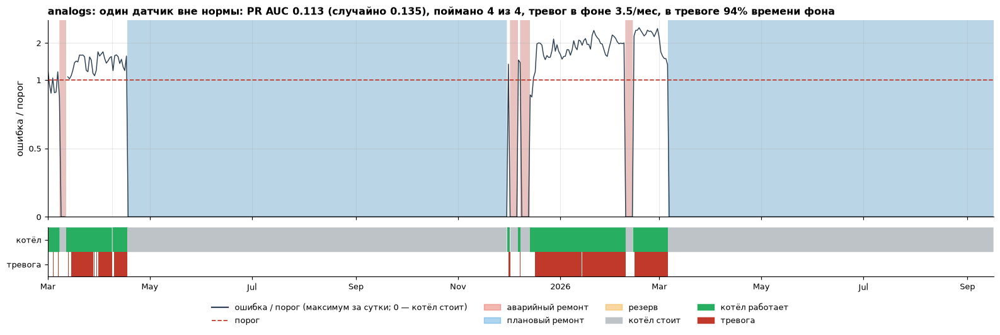


[31/40] Группа 1 · Перенос с другого котла · К-2; обучение: К-1
Группа 1 · К-2 · analogs
  Готово за 21.3 с; рассчитано 10668 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-2 · AAKR
  Готово за 2.1 мин; рассчитано 10668 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.046,0.049,0 из 3,0.000,0.000,0.000,11.8,0,50,1,9391.000,10668.000
analogs: несколько датчиков,0.041,0.049,3 из 3,0.068,1.000,0.127,50.2,7,96,12,9391.000,10668.000
analogs: медленный сдвиг (2 сут),0.049,0.049,3 из 3,0.103,1.000,0.188,88.6,3,26,3,9391.000,10668.000
AAKR: один датчик вне нормы,0.254,0.049,2 из 3,0.029,0.667,0.056,23.9,2,66,4,9391.000,10668.000
AAKR: несколько датчиков,0.183,0.049,3 из 3,0.106,1.000,0.192,90.1,5,42,2,9391.000,10668.000
AAKR: медленный сдвиг (2 сут),0.619,0.049,3 из 3,0.231,1.000,0.375,100.0,3,10,2,9391.000,10668.000



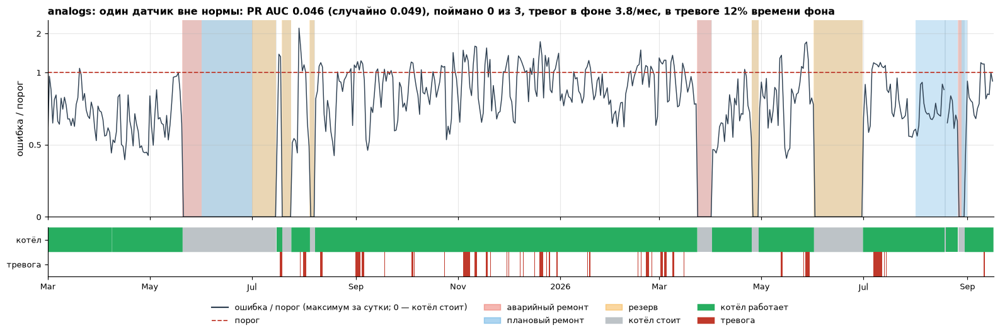


[32/40] Группа 1 · Перенос с другого котла · К-2; обучение: К-3
Группа 1 · К-2 · analogs
  Готово за 20.6 с; рассчитано 10668 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-2 · AAKR
  Готово за 2.1 мин; рассчитано 10668 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.030,0.049,2 из 3,0.048,0.667,0.089,54.7,5,100,5,9391.000,10668.000
analogs: несколько датчиков,0.032,0.049,3 из 3,0.081,1.000,0.151,69.9,7,79,10,9391.000,10668.000
analogs: медленный сдвиг (2 сут),0.030,0.049,3 из 3,0.231,1.000,0.375,100.0,3,10,2,9391.000,10668.000
AAKR: один датчик вне нормы,0.029,0.049,0 из 3,0.000,0.000,0.000,19.4,0,49,0,9391.000,10668.000
AAKR: несколько датчиков,0.031,0.049,3 из 3,0.133,1.000,0.235,90.6,6,39,5,9391.000,10668.000
AAKR: медленный сдвиг (2 сут),0.039,0.049,3 из 3,0.097,1.000,0.176,76.9,3,28,5,9391.000,10668.000



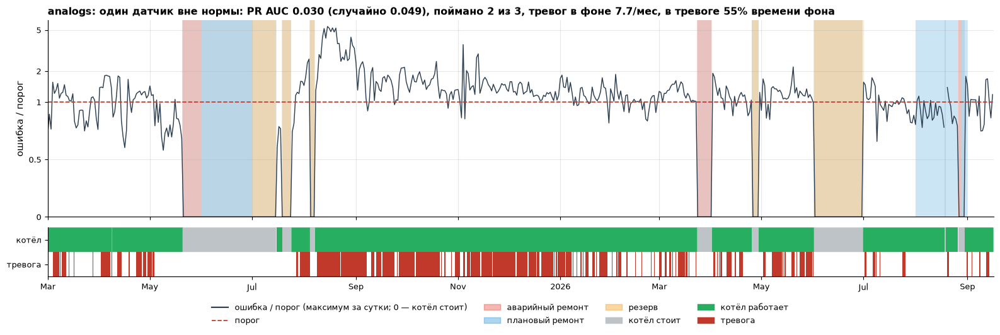


[33/40] Группа 1 · Перенос с другого котла · К-2; обучение: К-4
Группа 1 · К-2 · analogs
  Готово за 21.0 с; рассчитано 10668 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-2 · AAKR
  Готово за 2.1 мин; рассчитано 10668 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.058,0.049,3 из 3,0.044,1.000,0.084,52.8,4,87,7,9391.000,10668.000
analogs: несколько датчиков,0.053,0.049,3 из 3,0.066,1.000,0.123,68.8,5,71,3,9391.000,10668.000
analogs: медленный сдвиг (2 сут),0.060,0.049,3 из 3,0.086,1.000,0.158,77.3,3,32,2,9391.000,10668.000
AAKR: один датчик вне нормы,0.099,0.049,3 из 3,0.045,1.000,0.086,72.4,3,64,5,9391.000,10668.000
AAKR: несколько датчиков,0.074,0.049,3 из 3,0.071,1.000,0.133,90.7,3,39,2,9391.000,10668.000
AAKR: медленный сдвиг (2 сут),0.165,0.049,3 из 3,0.200,1.000,0.333,85.9,3,12,2,9391.000,10668.000



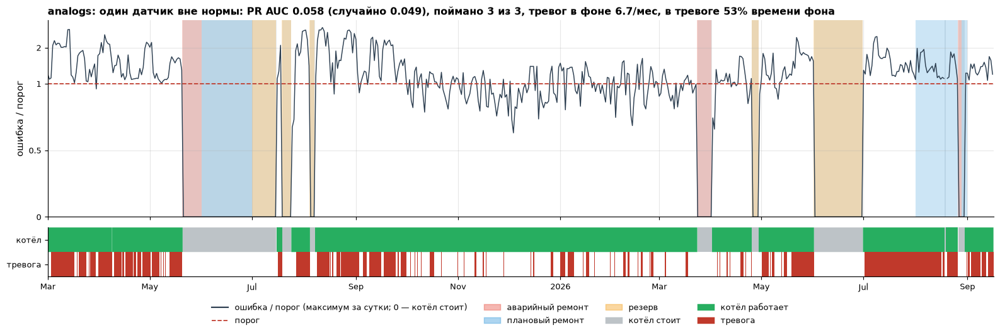


[34/40] Группа 1 · Перенос с другого котла · К-3; обучение: К-1
Группа 1 · К-3 · analogs
  Готово за 20.9 с; рассчитано 9932 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-3 · AAKR
  Готово за 2.0 мин; рассчитано 9932 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.220,0.212,6 из 8,0.234,0.750,0.357,37.9,11,36,13,4094.000,9932.000
analogs: несколько датчиков,0.220,0.212,7 из 8,0.324,0.875,0.473,93.4,12,25,13,4094.000,9932.000
analogs: медленный сдвиг (2 сут),0.207,0.212,7 из 8,0.333,0.875,0.483,100.0,9,18,10,4094.000,9932.000
AAKR: один датчик вне нормы,0.275,0.212,7 из 8,0.293,0.875,0.439,68.2,12,29,12,4094.000,9932.000
AAKR: несколько датчиков,0.313,0.212,7 из 8,0.333,0.875,0.483,100.0,9,18,10,4094.000,9932.000
AAKR: медленный сдвиг (2 сут),0.247,0.212,7 из 8,0.333,0.875,0.483,100.0,9,18,10,4094.000,9932.000



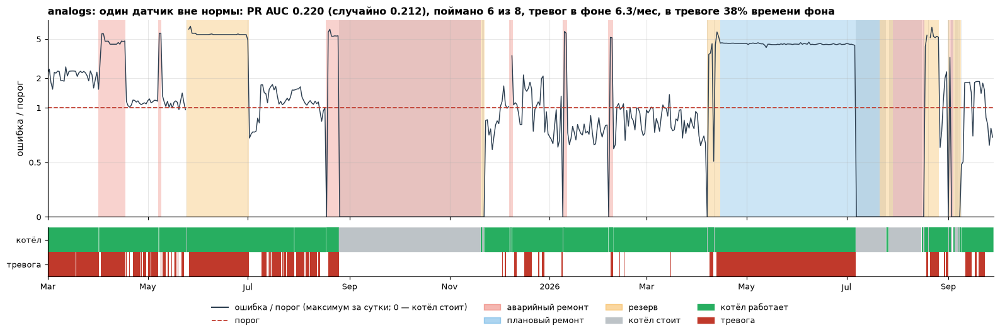


[35/40] Группа 1 · Перенос с другого котла · К-3; обучение: К-2
Группа 1 · К-3 · analogs
  Готово за 19.4 с; рассчитано 9932 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-3 · AAKR
  Готово за 2.0 мин; рассчитано 9932 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.174,0.212,7 из 8,0.393,0.875,0.542,96.4,11,17,12,4094.000,9932.000
analogs: несколько датчиков,0.206,0.212,7 из 8,0.333,0.875,0.483,98.9,9,18,9,4094.000,9932.000
analogs: медленный сдвиг (2 сут),0.155,0.212,7 из 8,0.321,0.875,0.470,99.5,9,19,10,4094.000,9932.000
AAKR: один датчик вне нормы,0.199,0.212,7 из 8,0.333,0.875,0.483,99.5,10,20,12,4094.000,9932.000
AAKR: несколько датчиков,0.239,0.212,7 из 8,0.333,0.875,0.483,100.0,9,18,10,4094.000,9932.000
AAKR: медленный сдвиг (2 сут),0.180,0.212,7 из 8,0.333,0.875,0.483,100.0,9,18,10,4094.000,9932.000



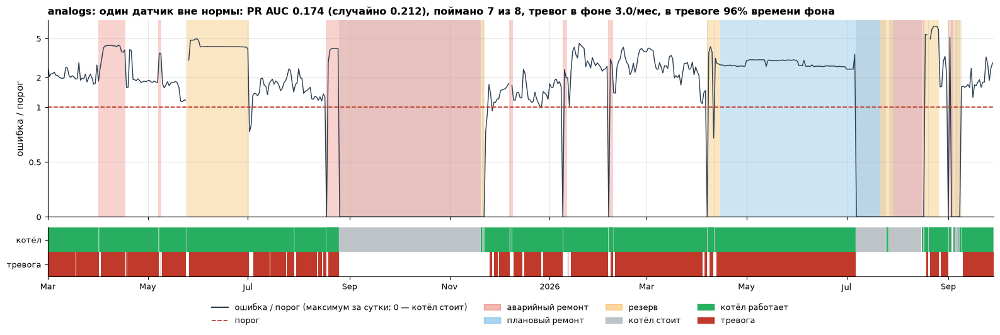


[36/40] Группа 1 · Перенос с другого котла · К-3; обучение: К-4
Группа 1 · К-3 · analogs
  Готово за 19.5 с; рассчитано 9932 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-3 · AAKR
  Готово за 2.0 мин; рассчитано 9932 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.242,0.212,7 из 8,0.255,0.875,0.395,46.3,13,38,15,4094.000,9932.000
analogs: несколько датчиков,0.236,0.212,7 из 8,0.304,0.875,0.452,63.8,14,32,13,4094.000,9932.000
analogs: медленный сдвиг (2 сут),0.199,0.212,7 из 8,0.257,0.875,0.397,85.8,9,26,11,4094.000,9932.000
AAKR: один датчик вне нормы,0.248,0.212,7 из 8,0.278,0.875,0.422,94.7,10,26,12,4094.000,9932.000
AAKR: несколько датчиков,0.253,0.212,7 из 8,0.343,0.875,0.493,93.3,12,23,11,4094.000,9932.000
AAKR: медленный сдвиг (2 сут),0.189,0.212,7 из 8,0.379,0.875,0.529,100.0,11,18,10,4094.000,9932.000



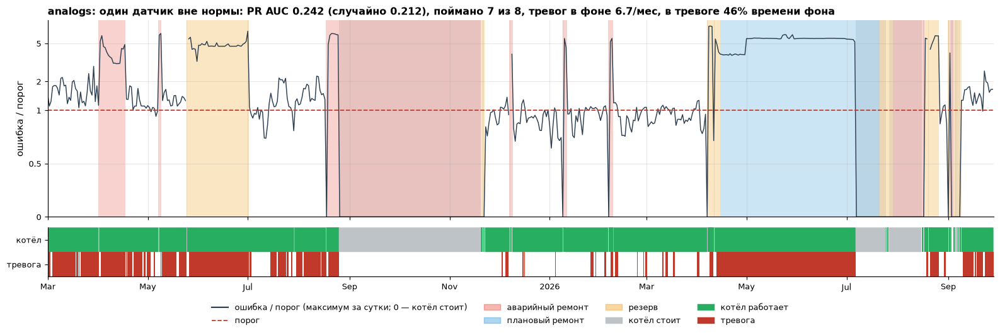


[37/40] Группа 1 · Перенос с другого котла · К-4; обучение: К-1
Группа 1 · К-4 · analogs
  Готово за 18.7 с; рассчитано 7816 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-4 · AAKR
  Готово за 1.6 мин; рассчитано 7816 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.125,0.115,5 из 5,0.162,1.000,0.278,74.9,11,57,6,6295.000,7816.000
analogs: несколько датчиков,0.110,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000
analogs: медленный сдвиг (2 сут),0.109,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000
AAKR: один датчик вне нормы,0.119,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000
AAKR: несколько датчиков,0.134,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000
AAKR: медленный сдвиг (2 сут),0.103,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000



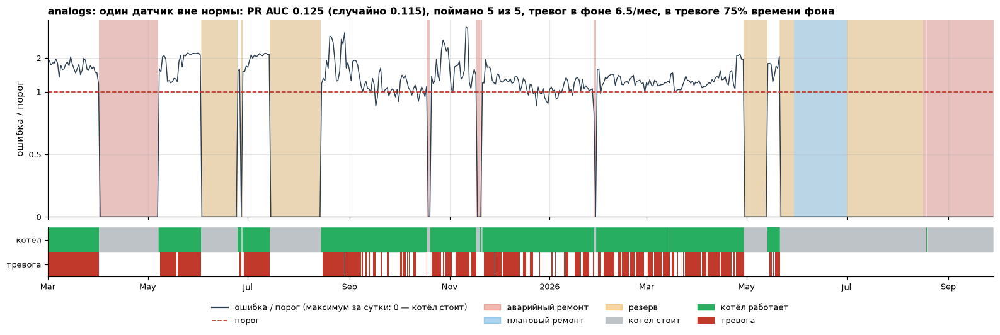


[38/40] Группа 1 · Перенос с другого котла · К-4; обучение: К-2
Группа 1 · К-4 · analogs
  Готово за 18.2 с; рассчитано 7816 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-4 · AAKR
  Готово за 1.6 мин; рассчитано 7816 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.155,0.115,5 из 5,0.176,1.000,0.300,92.6,6,28,0,6295.000,7816.000
analogs: несколько датчиков,0.154,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000
analogs: медленный сдвиг (2 сут),0.151,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000
AAKR: один датчик вне нормы,0.193,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000
AAKR: несколько датчиков,0.165,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000
AAKR: медленный сдвиг (2 сут),0.164,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000



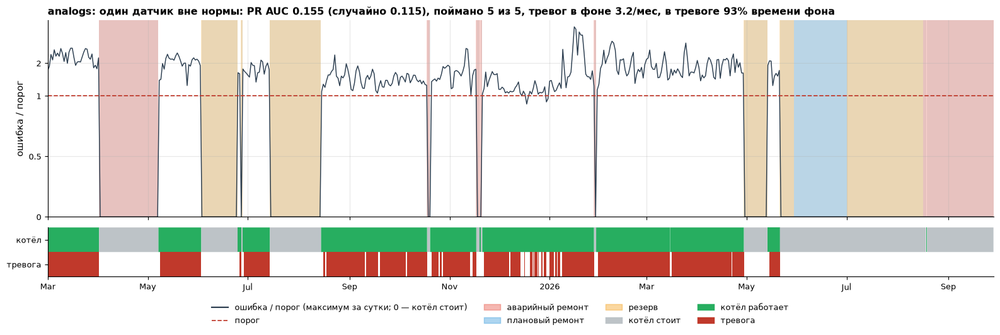


[39/40] Группа 1 · Перенос с другого котла · К-4; обучение: К-3
Группа 1 · К-4 · analogs
  Готово за 19.6 с; рассчитано 7816 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 1 · К-4 · AAKR
  Готово за 1.6 мин; рассчитано 7816 ч; обучений: 0; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.121,0.115,5 из 5,0.155,1.000,0.269,75.3,9,49,1,6295.000,7816.000
analogs: несколько датчиков,0.145,0.115,5 из 5,0.153,1.000,0.265,75.3,9,50,1,6295.000,7816.000
analogs: медленный сдвиг (2 сут),0.126,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000
AAKR: один датчик вне нормы,0.195,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000
AAKR: несколько датчиков,0.187,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000
AAKR: медленный сдвиг (2 сут),0.175,0.115,5 из 5,0.333,1.000,0.500,100.0,5,10,0,6295.000,7816.000



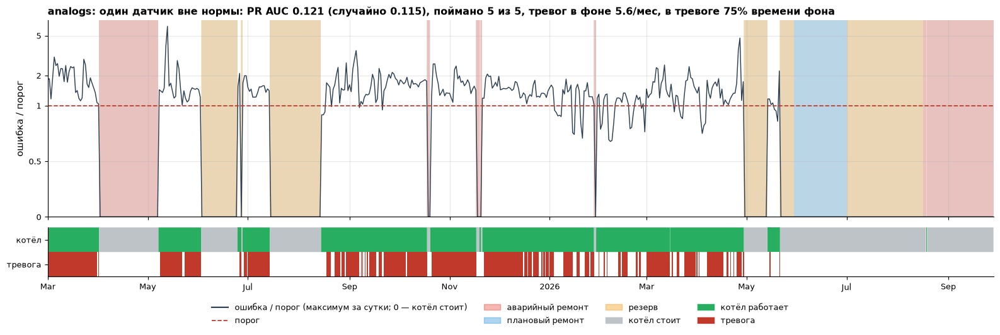


[40/40] Группа 3 · Индивидуальная · свои датчики · К-8; обучение: К-8
Группа 3 · К-8 · analogs
  Готово за 1.0 мин; рассчитано 6926 ч; обучений: 19; экспорт: финальных 1, месячных 19; оценки: расчёт.
Группа 3 · К-8 · AAKR
  Готово за 11.4 мин; рассчитано 6926 ч; обучений: 19; экспорт: финальных 1, месячных 19; оценки: расчёт.


view,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,% фона в тревоге,полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
analogs: один датчик вне нормы,0.181,0.130,0 из 5,0.000,0.000,0.000,2.3,0,1,2,5383.000,6926.000
analogs: несколько датчиков,0.197,0.130,0 из 5,0.000,0.000,0.000,2.0,0,3,1,5383.000,6926.000
analogs: медленный сдвиг (2 сут),0.173,0.130,2 из 5,0.333,0.400,0.364,4.6,2,4,2,5383.000,6926.000
AAKR: один датчик вне нормы,0.166,0.130,0 из 5,0.000,0.000,0.000,3.2,0,7,1,5383.000,6926.000
AAKR: несколько датчиков,0.208,0.130,0 из 5,0.000,0.000,0.000,1.9,0,2,1,5383.000,6926.000
AAKR: медленный сдвиг (2 сут),0.486,0.130,3 из 5,0.273,0.600,0.375,22.3,3,8,1,5383.000,6926.000



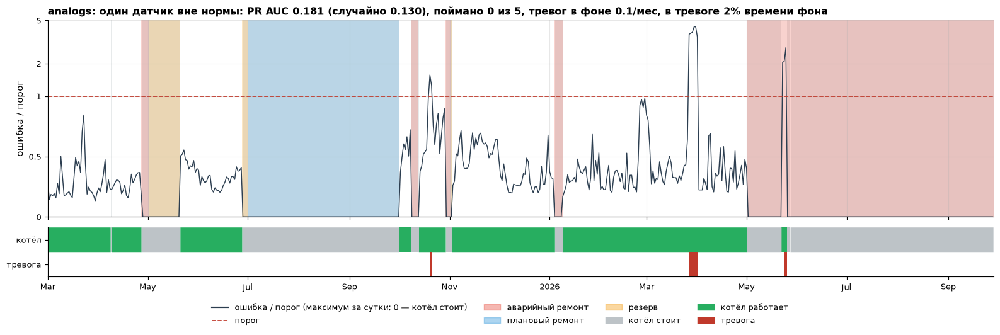


Завершено: 40 экспериментов; ошибок: 0. Таблицы и графики — в следующих ячейках.


In [24]:
RESULT = LF.run(CFG)


<a id="overview"></a>
## 3. Основные метрики

PR AUC сохраняет прежнее название и расчёт `average_precision_score`.
Рядом показан **PR AUC случайный уровень**: доля часов перед аварией среди часов,
использованных для PR AUC (перед аварией + фон). Например, 0.10 означает базовый уровень 10%.
Он рассчитан на тех же доступных часах конкретной модели и окна; нейтральные часы исключены.
Recall — доля остановов с тревогой; Precision — доля полезных эпизодов среди полезных и фоновых.
Нейтральная полоса перед окном, как в legacy, не считается фоном; её эпизоды показаны отдельно в деталях.
F1 объединяет событийный Recall и эпизодный Precision по прежней формуле legacy; это разные единицы учёта.

При `overlap` продолжающаяся тревога засчитывается, даже если началась раньше окна.
При `start` — только начавшаяся в окне. Не вводятся ограничения по минимальной полноте окна перед остановом.
Процент фона в тревоге считается по подтверждённым эпизодам, а не по одиночным превышениям порога.
Упреждение — от начала эпизода, как в legacy; оно не означает установленную дату появления дефекта.

Рядом выведены количества полезных, фоновых и нейтральных эпизодов, часы фона и реально оценённые рабочие часы.
«% фона в тревоге» показан в процентах (например, 12.5 означает 12.5%); PR AUC, Precision и Recall — доли от 0 до 1.


In [25]:
LF.show_overview(RESULT)


group,scenario,target,donors,sensor_set,key,status,seconds
Группа 2,local_common,К-5,К-5,common,local_common__К-5__v22__fast,из сохранённого отчёта,0.280
Группа 2,local_full,К-5,К-5,full,local_full__К-5__v22__fast,готово,333.910
Группа 2,local_common,К-6,К-6,common,local_common__К-6__v22__fast,готово,380.640
Группа 2,local_full,К-6,К-6,full,local_full__К-6__v22__fast,готово,429.700
Группа 2,local_common,К-7,К-7,common,local_common__К-7__v22__fast,готово,423.380
Группа 2,local_full,К-7,К-7,full,local_full__К-7__v22__fast,готово,425.310
Группа 2,pooled,К-5,"К-5, К-6, К-7",common,pooled__К-5_К-6_К-7__v22__fast,готово,481.630
Группа 2,pooled,К-6,"К-5, К-6, К-7",common,pooled__К-5_К-6_К-7__v22__fast,готово,162.260
Группа 2,pooled,К-7,"К-5, К-6, К-7",common,pooled__К-5_К-6_К-7__v22__fast,готово,146.110
Группа 2,transfer,К-5,К-6,common,transfer__К-6__v22__fast,готово,127.660


group,scenario,target,status
Группа 3,pooled,К-8,неприменимо: в группе один котёл
Группа 3,transfer,К-8,неприменимо: в группе один котёл


group,scenario,target,donors,view,источник оценок,PR AUC,PR AUC случайный уровень,поймано аварий,precision,recall,F1,тревог в фоне в месяц,% фона в тревоге,"упреждение, ч",полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
Группа 2,local_common,К-5,К-5,analogs: один датчик вне нормы,fast,0.204,0.095,0 из 5,0.000,0.000,0.000,0.418,1.2,—,0,3,0,5171.000,6171.000
Группа 2,local_common,К-5,К-5,analogs: несколько датчиков,fast,0.123,0.095,0 из 5,0.000,0.000,0.000,0.557,1.3,—,0,4,1,5171.000,6171.000
Группа 2,local_common,К-5,К-5,analogs: медленный сдвиг (2 сут),fast,0.380,0.095,2 из 5,0.400,0.400,0.400,0.418,3.1,157.500,2,3,0,5171.000,6171.000
Группа 2,local_common,К-5,К-5,AAKR: один датчик вне нормы,fast,0.215,0.095,0 из 5,0.000,0.000,0.000,0.557,1.2,—,0,4,2,5171.000,6171.000
Группа 2,local_common,К-5,К-5,AAKR: несколько датчиков,fast,0.110,0.095,0 из 5,0.000,0.000,0.000,0.557,1.6,—,0,4,1,5171.000,6171.000
Группа 2,local_common,К-5,К-5,AAKR: медленный сдвиг (2 сут),fast,0.309,0.095,3 из 5,0.571,0.600,0.585,0.418,3.3,127.000,4,3,0,5171.000,6171.000
Группа 2,local_full,К-5,К-5,analogs: один датчик вне нормы,fast,0.233,0.094,0 из 5,0.000,0.000,0.000,0.834,0.9,—,0,6,0,5177.000,6177.000
Группа 2,local_full,К-5,К-5,analogs: несколько датчиков,fast,0.154,0.094,0 из 5,0.000,0.000,0.000,0.834,0.9,—,0,6,0,5177.000,6177.000
Группа 2,local_full,К-5,К-5,analogs: медленный сдвиг (2 сут),fast,0.375,0.094,2 из 5,0.400,0.400,0.400,0.417,4.2,157.500,2,3,0,5177.000,6177.000
Группа 2,local_full,К-5,К-5,AAKR: один датчик вне нормы,fast,0.202,0.094,0 из 5,0.000,0.000,0.000,0.556,1.0,—,0,4,1,5177.000,6177.000


<a id="details"></a>
## 4. Графики и каждый останов

Раскрывайте группу, сценарий, котёл и метод. Возвращён график из прежнего ноутбука:
сверху — **суточный максимум ошибки / порога**, серые простои и цветные периоды
аварийного ремонта, планового ремонта и резерва. В заголовке — PR AUC, случайный
уровень, пойманные аварии, частота фоновых тревог и доля фона в тревоге.
Снизу — прежняя общая полоса «котёл / тревога»: зелёная работа, серый простой,
красные эпизоды тревог. Цвета, подписи и легенда прежние.

Сохранено только новое масштабирование оценки: до порога 1 шкала линейная,
выше 1 — сжатая. Пики не обрезаются на 5. Дополнительных цветных окон,
третьей панели и раздельной окраски тревог нет.

Ниже можно выбрать даты без обучения. Обрезка графика не пересчитывает тревоги;
метрики в заголовке относятся ко всему периоду эксперимента.


Отрисовка: legacy-original-2panel-2.2.1 · C:\Users\ZaprutoEA\Desktop\ЦД\legacy\lib\legacy_plots.py



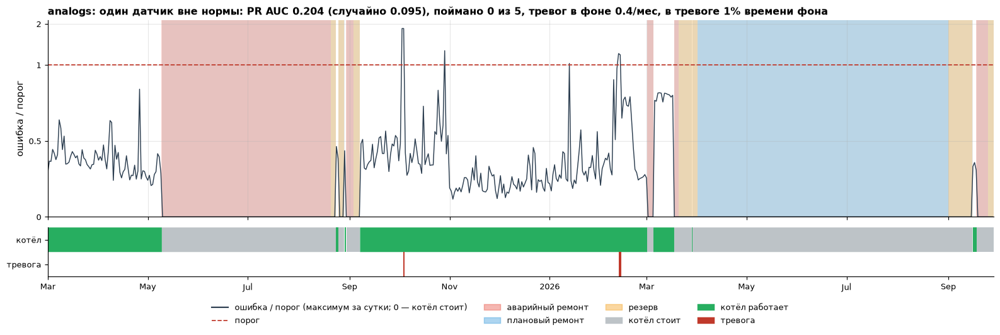
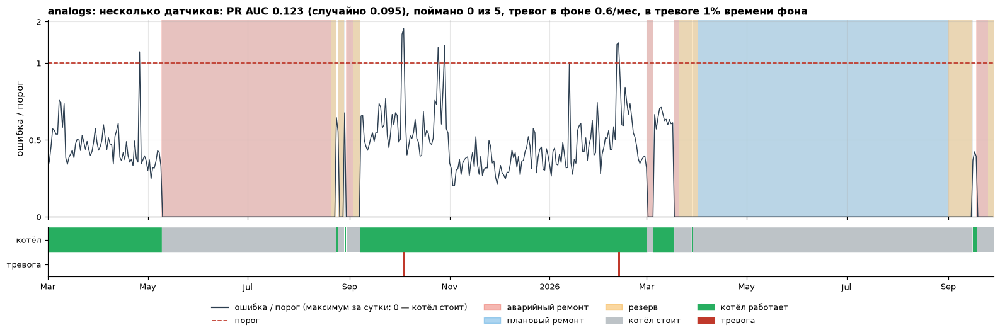
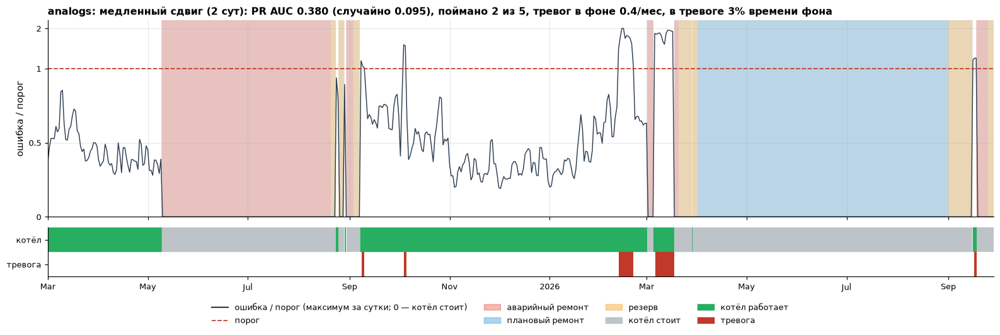
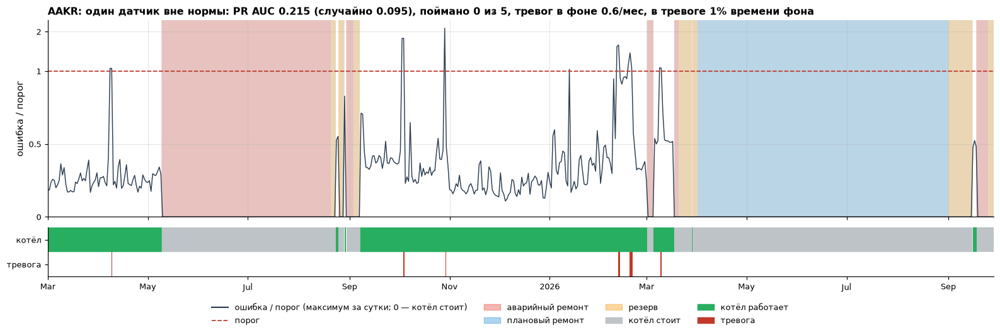
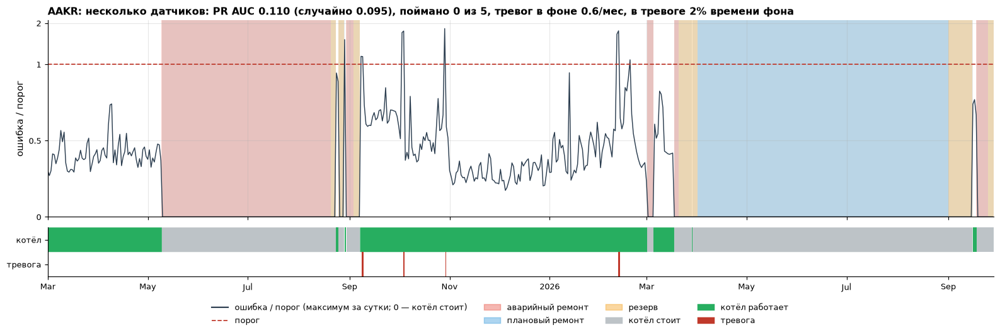
...
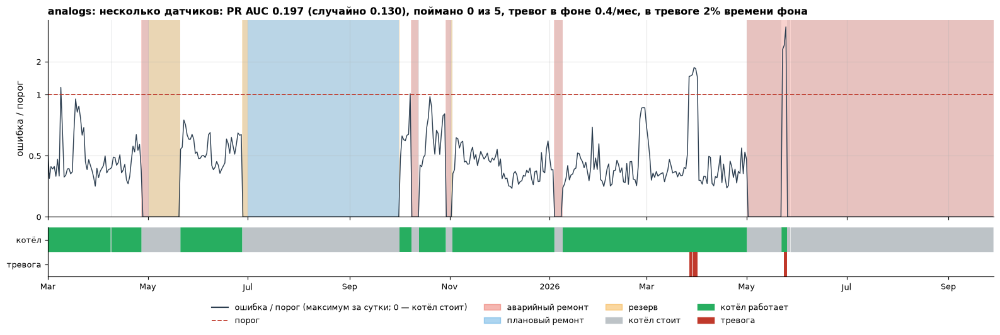
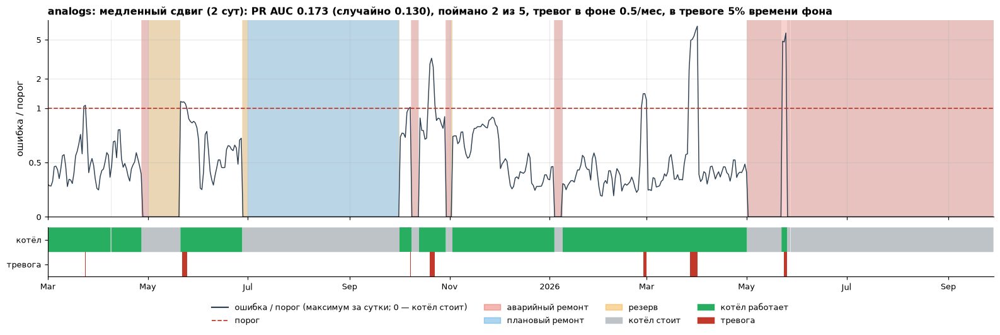
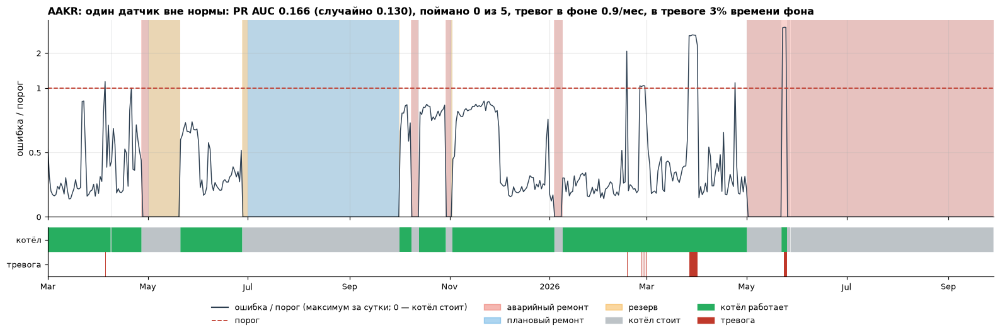
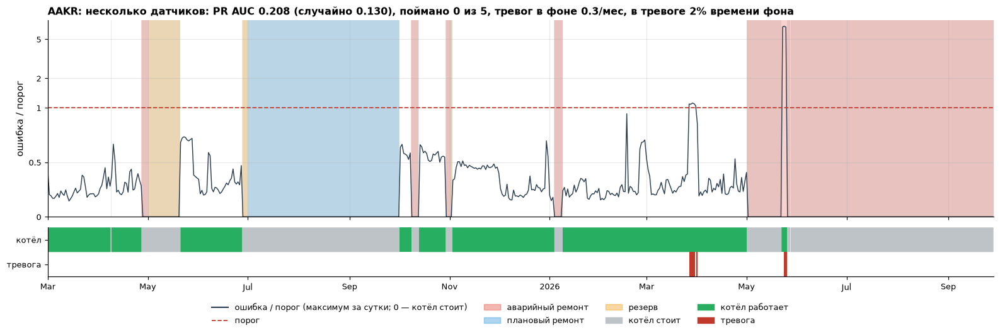
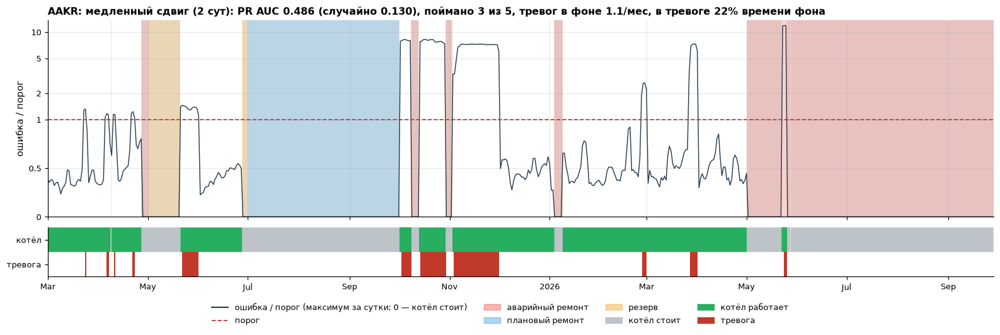

In [26]:
# Загрузить заменённый файл графиков с диска, даже если ядро уже работало.
import importlib
import legacy_plots
importlib.invalidate_caches()
legacy_plots = importlib.reload(legacy_plots)
print('Отрисовка:', legacy_plots.PLOT_VERSION, '·', legacy_plots.__file__)
LF.show_details(RESULT)


### Отдельный период
Выберите эксперимент и даты. Для первого просмотра настройки берутся из первого готового эксперимента; затем их можно менять.
Раскомментируйте последнюю строку, чтобы вывести график выбранного периода.


In [27]:
if RESULT['records']:
    _record = RESULT['records'][0]
    DETAIL_PERIOD = dict(
        group=_record['meta']['group'], target=_record['meta']['target'],
        scenario=_record['meta']['scenario'], donors=_record['meta']['donors'],
        view=next(iter(_record['views'])),
        start=None, end=None,  # например, start='2025-06-01', end='2025-07-01' (правая граница не включается)
    )
    # LF.show_period(RESULT, **DETAIL_PERIOD)


<a id="thresholds"></a>
## 5. Сравнение порогов — без обучения заново

1.0 — исходный порог каждого месяца; 0.75 — на 25% ниже, 1.5 — на 50% выше.
Для каждого варианта заново формируются тревоги и считаются Precision, Recall, F1, число и длительность фоновых тревог.
PR AUC при умножении всех порогов на одну константу остаётся тем же.

Это диагностическая таблица, автоматического выбора самого красивого порога по будущим остановам нет.
Если задан `THRESHOLD_VALIDATION_END`, отдельно показываются прошлая проверка и последующий контроль.
Выбирать порог следует по прошлой части, оценивать выбранный вариант — по последующей.


In [28]:
LF.show_table(RESULT, 'thresholds')


donors,method,view,источник оценок,множитель порога,период,PR AUC,PR AUC случайный уровень,поймано аварий,найдено,всего остановов,precision,recall,F1,тревог в фоне в месяц,% фона в тревоге,"упреждение, ч",полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
К-5,analogs,analogs: один датчик вне нормы,fast,0.500,весь период: диагностический,0.204,0.095,1 из 5,1,5,0.048,0.200,0.077,2.785,5.2,281.000,1,20,1,5171.000,6171.000
К-5,analogs,analogs: один датчик вне нормы,fast,0.750,весь период: диагностический,0.204,0.095,1 из 5,1,5,0.250,0.200,0.222,0.835,1.8,241.000,2,6,3,5171.000,6171.000
К-5,analogs,analogs: один датчик вне нормы,fast,1.000,весь период: диагностический,0.204,0.095,0 из 5,0,5,0.000,0.000,0.000,0.418,1.2,—,0,3,0,5171.000,6171.000
К-5,analogs,analogs: один датчик вне нормы,fast,1.250,весь период: диагностический,0.204,0.095,0 из 5,0,5,0.000,0.000,0.000,0.139,0.3,—,0,1,0,5171.000,6171.000
К-5,analogs,analogs: один датчик вне нормы,fast,1.500,весь период: диагностический,0.204,0.095,0 из 5,0,5,0.000,0.000,0.000,0.139,0.3,—,0,1,0,5171.000,6171.000
К-5,analogs,analogs: один датчик вне нормы,fast,2.000,весь период: диагностический,0.204,0.095,0 из 5,0,5,—,0.000,—,0.000,0.0,—,0,0,0,5171.000,6171.000
К-5,analogs,analogs: несколько датчиков,fast,0.500,весь период: диагностический,0.123,0.095,2 из 5,2,5,0.056,0.400,0.098,4.734,18.3,204.000,2,34,2,5171.000,6171.000
К-5,analogs,analogs: несколько датчиков,fast,0.750,весь период: диагностический,0.123,0.095,0 из 5,0,5,0.000,0.000,0.000,0.835,2.4,—,0,6,2,5171.000,6171.000
К-5,analogs,analogs: несколько датчиков,fast,1.000,весь период: диагностический,0.123,0.095,0 из 5,0,5,0.000,0.000,0.000,0.557,1.3,—,0,4,1,5171.000,6171.000
К-5,analogs,analogs: несколько датчиков,fast,1.250,весь период: диагностический,0.123,0.095,0 из 5,0,5,0.000,0.000,0.000,0.418,0.8,—,0,3,0,5171.000,6171.000


<a id="proximity"></a>
## 6. Близость к следующему останову — отдельный эксперимент

Вес часа = `2 ** (-дни_до_останова / полураспад_веса)` перед следующим аварийным остановом;
перед следующей плановой заявкой/резервом вес равен нулю. За полураспад вес уменьшается вдвое.
PR близости строится по плавным весам вместо двоичной разметки. Это **не обычный PR AUC** и не вероятность аварии.
Все одинаковые оценки включаются одновременно. Постоянный сигнал даёт средний вес, показанный в столбце «базовый вес».
Часы после последней известной заявки не оцениваются: неизвестно, когда следующий останов.
Последние `MIN_LEAD_H` часов исключаются. Метрика оценивает связь сигнала с приближением останова;
сама по себе она не поощряет наиболее полезное раннее предупреждение.


In [29]:
LF.show_table(RESULT, 'proximity')


donors,method,view,источник оценок,"полураспад веса, сут",PR близости (эксперимент),базовый вес,часов проверки
К-5,analogs,analogs: один датчик вне нормы,fast,1,0.036,0.019,6162.000
К-5,analogs,analogs: один датчик вне нормы,fast,3,0.107,0.053,6162.000
К-5,analogs,analogs: один датчик вне нормы,fast,7,0.214,0.109,6162.000
К-5,analogs,analogs: один датчик вне нормы,fast,14,0.314,0.193,6162.000
К-5,analogs,analogs: несколько датчиков,fast,1,0.021,0.019,6162.000
К-5,analogs,analogs: несколько датчиков,fast,3,0.064,0.053,6162.000
К-5,analogs,analogs: несколько датчиков,fast,7,0.143,0.109,6162.000
К-5,analogs,analogs: несколько датчиков,fast,14,0.238,0.193,6162.000
К-5,analogs,analogs: медленный сдвиг (2 сут),fast,1,0.078,0.019,6162.000
К-5,analogs,analogs: медленный сдвиг (2 сут),fast,3,0.192,0.053,6162.000


## 7. Зависимость от окна предупреждения

Для каждого окна отдельно показаны те же основные метрики и фактическое число часов фона.
Сравнивать сценарии нужно внутри одного окна. Увеличение окна не является улучшением самой модели.


In [30]:
LF.show_table(RESULT, 'windows')


donors,method,view,источник оценок,"окно, сут",PR AUC,PR AUC случайный уровень,поймано аварий,найдено,всего остановов,precision,recall,F1,тревог в фоне в месяц,% фона в тревоге,"упреждение, ч",полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
К-5,analogs,analogs: один датчик вне нормы,fast,1,0.034,0.015,0 из 5,0,5,0.000,0.000,0.000,0.389,1.1,—,0,3,0,5548.000,6171.000
К-5,analogs,analogs: один датчик вне нормы,fast,3,0.116,0.042,0 из 5,0,5,0.000,0.000,0.000,0.400,1.1,—,0,3,0,5404.000,6171.000
К-5,analogs,analogs: один датчик вне нормы,fast,7,0.204,0.095,0 из 5,0,5,0.000,0.000,0.000,0.418,1.2,—,0,3,0,5171.000,6171.000
К-5,analogs,analogs: один датчик вне нормы,fast,14,0.444,0.170,0 из 5,0,5,0.000,0.000,0.000,0.298,0.5,—,0,2,1,4835.000,6171.000
К-5,analogs,analogs: один датчик вне нормы,fast,30,0.495,0.302,1 из 5,1,5,0.333,0.200,0.250,0.354,0.6,421.000,1,2,0,4068.000,6171.000
К-5,analogs,analogs: несколько датчиков,fast,1,0.017,0.015,0 из 5,0,5,0.000,0.000,0.000,0.649,1.2,—,0,5,0,5548.000,6171.000
К-5,analogs,analogs: несколько датчиков,fast,3,0.049,0.042,0 из 5,0,5,0.000,0.000,0.000,0.666,1.3,—,0,5,0,5404.000,6171.000
К-5,analogs,analogs: несколько датчиков,fast,7,0.123,0.095,0 из 5,0,5,0.000,0.000,0.000,0.557,1.3,—,0,4,1,5171.000,6171.000
К-5,analogs,analogs: несколько датчиков,fast,14,0.289,0.170,1 из 5,1,5,0.250,0.200,0.222,0.447,0.8,323.000,1,3,1,4835.000,6171.000
К-5,analogs,analogs: несколько датчиков,fast,30,0.395,0.302,2 из 5,2,5,0.400,0.400,0.400,0.531,1.0,375.000,2,3,0,4068.000,6171.000


<a id="paired"></a>
## 8. Индивидуальная и общая модель на одинаковых часах

Каждая пара сравнивается отдельно на общем наборе датчиков и пересечении реально рассчитанных часов.
Общее пересечение сразу всех сценариев не используется. Эпизоды тревог формируются на полном ряду,
поэтому исключение часов из сравнения не создаёт новые начала тревог.


In [31]:
PAIRED = LF.paired_comparison(RESULT)
display(HTML(LF._table(PAIRED)))


group,target,view,сравнение,scenario,donors,PR AUC,PR AUC случайный уровень,поймано аварий,найдено,всего остановов,precision,recall,F1,тревог в фоне в месяц,% фона в тревоге,"упреждение, ч",полезных эпизодов,фоновых эпизодов,нейтральных эпизодов,часов фона,рассчитано рабочих часов
Группа 2,К-5,AAKR: медленный сдвиг (2 сут),pooled__К-5_К-6_К-7__v22__fast,local_common,К-5,0.309,0.095,3 из 5,3,5,0.571,0.600,0.585,0.418,3.3,127.000,4,3,0,5171.000,6171.000
Группа 2,К-5,AAKR: медленный сдвиг (2 сут),pooled__К-5_К-6_К-7__v22__fast,pooled,"К-5, К-6, К-7",0.197,0.095,0 из 5,0,5,0.000,0.000,0.000,0.139,1.5,—,0,1,0,5171.000,6171.000
Группа 2,К-5,AAKR: несколько датчиков,pooled__К-5_К-6_К-7__v22__fast,local_common,К-5,0.110,0.095,0 из 5,0,5,0.000,0.000,0.000,0.557,1.6,—,0,4,1,5171.000,6171.000
Группа 2,К-5,AAKR: несколько датчиков,pooled__К-5_К-6_К-7__v22__fast,pooled,"К-5, К-6, К-7",0.120,0.095,0 из 5,0,5,0.000,0.000,0.000,0.418,1.0,—,0,3,2,5171.000,6171.000
Группа 2,К-5,AAKR: один датчик вне нормы,pooled__К-5_К-6_К-7__v22__fast,local_common,К-5,0.215,0.095,0 из 5,0,5,0.000,0.000,0.000,0.557,1.2,—,0,4,2,5171.000,6171.000
Группа 2,К-5,AAKR: один датчик вне нормы,pooled__К-5_К-6_К-7__v22__fast,pooled,"К-5, К-6, К-7",0.129,0.095,0 из 5,0,5,0.000,0.000,0.000,0.418,2.2,—,0,3,0,5171.000,6171.000
Группа 2,К-5,analogs: медленный сдвиг (2 сут),pooled__К-5_К-6_К-7__v22__fast,local_common,К-5,0.380,0.095,2 из 5,2,5,0.400,0.400,0.400,0.418,3.1,157.500,2,3,0,5171.000,6171.000
Группа 2,К-5,analogs: медленный сдвиг (2 сут),pooled__К-5_К-6_К-7__v22__fast,pooled,"К-5, К-6, К-7",0.129,0.095,0 из 5,0,5,0.000,0.000,0.000,0.278,2.2,—,0,2,0,5171.000,6171.000
Группа 2,К-5,analogs: несколько датчиков,pooled__К-5_К-6_К-7__v22__fast,local_common,К-5,0.123,0.095,0 из 5,0,5,0.000,0.000,0.000,0.557,1.3,—,0,4,1,5171.000,6171.000
Группа 2,К-5,analogs: несколько датчиков,pooled__К-5_К-6_К-7__v22__fast,pooled,"К-5, К-6, К-7",0.107,0.095,0 из 5,0,5,0.000,0.000,0.000,0.278,0.7,—,0,2,1,5171.000,6171.000


<a id="diagnostics"></a>
## 9. Диагностика и сохранённые модели

Причины отсутствия результата показаны отдельно от основных метрик. Пропуски не объявляются нормой.
В разделе графиков есть таблица происхождения моделей: обучение, кэш или предыдущая модель.
Финальные модели — `models_legacy/<группа>/<эксперимент>/<котёл>/<метод>/final/`,
исторические — соседние папки `ГГГГ-ММ`. Готовые модели можно открыть в ноутбуке 03.
Служебный `fleet_report.joblib` сохраняет оценки и данные отчёта, чтобы восстановить таблицы без обучения.

Для просмотра уже готовых экспериментов после прерывания без продолжения обучения: `RESULT = LF.load_report(CFG)`.


In [32]:
LF.show_table(RESULT, 'hours')
if RESULT['errors']:
    display(pd.DataFrame(RESULT['errors'])[['group','scenario','target','donors','error']])
print('Ошибок:', len(RESULT['errors']))
print('Моделей экспортировано:', sum(len(r['exports']) for r in RESULT['records']))
# Для восстановления после перезапуска ядра вместо обучения:
# RESULT = LF.load_report(CFG)
# Для собственного анализа доступны RESULT['tables']['main'/'thresholds'/'proximity'/'events'/'windows'/'hours'].


donors,method,view,источник оценок,причина,часов
К-5,analogs,analogs: один датчик вне нормы,fast,котёл остановлен,7525.000
К-5,analogs,analogs: один датчик вне нормы,fast,рассчитано,6171.000
К-5,analogs,analogs: один датчик вне нормы,fast,пуск,131.000
К-5,analogs,analogs: один датчик вне нормы,fast,недостаточно датчиков,11.000
К-5,analogs,analogs: несколько датчиков,fast,котёл остановлен,7525.000
К-5,analogs,analogs: несколько датчиков,fast,рассчитано,6171.000
К-5,analogs,analogs: несколько датчиков,fast,пуск,131.000
К-5,analogs,analogs: несколько датчиков,fast,недостаточно датчиков,11.000
К-5,analogs,analogs: медленный сдвиг (2 сут),fast,котёл остановлен,7525.000
К-5,analogs,analogs: медленный сдвиг (2 сут),fast,рассчитано,6171.000


Ошибок: 0
Моделей экспортировано: 80
